# Oil price forecasting v2: factors, PCA, regimes and seasonality

Forecasts Brent front-month prices 1 to 60 trading days ahead, with daily automatic updates.

**What changed from v1**

| Area | v1 | v2 |
|---|---|---|
| Oil-market state | none | WTI futures curve slope (EIA contracts 1 and 4); crude inventories relative to their 5-year seasonal norm (EIA weekly) |
| Business cycle | daily rates only | adds 10Y–3M spread and the NY Fed Weekly Economic Index (WEI), aligned to release dates |
| Seasonality | none | Fourier calendar terms; seasonal anomalies for inventories and the 3-2-1 crack spread |
| Dimension reduction | LASSO only | adds PCA diffusion-index regression and targeted PCA (Bai & Ng 2008) |
| Regimes | none | real-time 2-state Gaussian HMM; regime prediction from macro variables; regime-dependent LASSO |
| Combination | none | equal-weight combination and regime-conditional inverse-MSE combination |
| LASSO | CV minimum, with intercept | adds a one-standard-error version; no intercept, so models shrink to the no-change forecast |
| Variables | some duplicates | removed duplicated series (`broad_usd`, `tnx`, `irx`), `hy_spread` (too short), spot prices (published with delays) |

**Real-time discipline.** Every feature is aligned to the date it would have been known. Low-frequency data enter from approximate release dates. Seasonal norms use prior years only. Regime probabilities are *filtered*, never smoothed. PCA and model selection run inside each rolling window. Section 19 checks this directly.

**How to use.** Check the paths in section 2, then Run All. Needs `yfinance` and `xlrd` (for EIA files) and internet access. Runtime is roughly 10–20 minutes for all six horizons; drop horizons in the config to go faster.

In [1]:
import inspect
import json
import time
import warnings
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path
from typing import List, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.linalg import matrix_power
from scipy import stats
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

/Users/heiheidaaaaaa/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/heiheidaaaaaa/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Configuration

Record `freeze_date` in the report. Nothing is tuned on dates from `test_start` onwards.

In [2]:
@dataclass
class Config:
    # ---- data ----
    target: str = "brent_fut"
    # quoted as levels / rates / indices: first differences plus the level
    level_series: List[str] = field(default_factory=lambda: [
        "vix", "ovx", "ust10y", "curve_10y2y", "t10y3m", "breakeven10y", "epu"])
    # never used as predictors (EIA spot prices are published with a delay)
    exclude: List[str] = field(default_factory=lambda: ["wti_spot", "brent_spot"])
    ffill_limit: int = 3            # max days to forward-fill daily series
    slow_ffill_limit: int = 7       # EIA futures files are updated weekly
    feature_lag: int = 0            # extra lag on all non-target daily features
    fred_lag: int = 1               # FRED daily series known the next day
    season_years: int = 5           # seasonal norm = same ISO week, previous 5 years
    weekly_stale_days: int = 21     # weekly value older than this -> missing

    # ---- sample split ----
    oos_start: str = "2016-01-01"   # pseudo out-of-sample (validation) start
    test_start: str = "2026-10-01"  # live test period
    freeze_date: str = "2026-10-10"

    # ---- forecasting ----
    horizons: List[int] = field(default_factory=lambda: [1, 5, 10, 20, 40, 60])
    window: int = 1260              # rolling estimation window (trading days)
    refit_every: int = 21           # refit every k days; forecast every day
    cv_folds: int = 5
    n_alphas: int = 40
    lasso_eps: float = 1e-2         # smallest alpha = eps * largest (tiny penalties only overfit)
    # False: regression forecasts shrink towards the no-change forecast instead of the
    # window mean (HistMean lost to RW at every horizon in v1, so the intercept adds noise)
    fit_intercept: bool = False
    pca_kmax: int = 8
    pca_k: Optional[int] = None     # None: Bai-Ng IC_p2 inside each window
    tpca_t: float = 1.65            # HAC |t| threshold for targeted predictors
    # features interacted with the regime probability in LASSO_RS
    rs_patterns: tuple = ("__lvl", "__anom", "20")

    # ---- regimes ----
    hmm_k: int = 2                  # number of states (last state = turbulent)
    hmm_inputs: List[str] = field(default_factory=lambda: ["ret"])   # also "absret5", "logrv20"
    hmm_min_obs: int = 500          # first fit after this many observations
    hmm_refit: int = 63             # re-estimate HMM every k days (filter daily)
    hmm_window: Optional[int] = None    # None = expanding window
    regime_C: float = 0.1           # inverse L2 penalty in the regime logit (strong: few episodes per window)

    # ---- forecast combination ----
    combo_pool: List[str] = field(default_factory=lambda: ["RW", "LASSO", "LASSO_1se", "PCA_reg", "TPCA", "LASSO_RS"])
    combo_lookback: int = 750
    combo_min_obs: int = 60
    combo_shrink: float = 0.5       # weight on equal weights vs inverse-MSE weights

    # ---- economic value / output ----
    cost_bps: float = 5.0
    trade_horizon: int = 1
    out_dir: str = "results_v2"
    seed: int = 0
    robustness_windows: List[int] = field(default_factory=lambda: [1260, 1512, 1764])
    model_list: Optional[List[str]] = None   # None = all models

cfg = Config()
OUT = Path(cfg.out_dir); OUT.mkdir(parents=True, exist_ok=True)
TS = pd.Timestamp(cfg.test_start)

## 2. Data

1. `yahoo_daily.csv` from the team repo.
2. Extra daily series. FRED series are taken from `fred_daily.csv` (written by `scripts/update_data.py`) when the column is there, otherwise downloaded. All FRED daily series are lagged one observation.
3. Weekly series from FRED: EIA crude stocks excluding SPR (`WCESTUS1`) and the NY Fed WEI. Each value enters on an approximate release date (period date + 6 days), which is conservative.
4. WTI futures contracts 1–4 from EIA, cached to `Data/raw/eia_wti_futures.csv`. If the download fails, put that file there by hand (EIA "Cushing, OK Crude Oil Future Contract 1–4", daily) and the notebook will use it.

In [3]:
RAW_YAHOO = "Data/raw/yahoo_daily.csv"
RAW_FRED = "Data/raw/fred_daily.csv"            # optional, from scripts/update_data.py
EIA_CACHE = "Data/raw/eia_wti_futures.csv"
PROCESSED = Path("Data/processed")
DOWNLOAD_START = "2000-01-01"

YAHOO_EXTRA = {"usdcad": "CAD=X", "usdnok": "NOK=X", "eem": "EEM"}
FRED_DAILY = {"ust10y": "DGS10", "curve_10y2y": "T10Y2Y", "t10y3m": "T10Y3M",
              "breakeven10y": "T10YIE", "ovx": "OVXCLS", "epu": "USEPUINDXD"}
# weekly: name -> (FRED id, release lag in days after the FRED date)
FRED_WEEKLY = {"crude_stocks": ("WCESTUS1", 6), "wei": ("WEI", 6)}
EIA_FUTURES = {"wti_c1": "RCLC1", "wti_c2": "RCLC2", "wti_c3": "RCLC3", "wti_c4": "RCLC4"}
EIA_URL = "https://www.eia.gov/dnav/pet/hist_xls/{sid}d.xls"

def fred_csv(sid, start=DOWNLOAD_START):
    x = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd={start}")
    s = pd.Series(pd.to_numeric(x.iloc[:, 1], errors="coerce").to_numpy(),
                  index=pd.to_datetime(x.iloc[:, 0]))
    return s.dropna().sort_index()

def yahoo_close(ticker, start=DOWNLOAD_START):
    import yfinance as yf
    x = yf.download(ticker, start=start, auto_adjust=False, progress=False, threads=False)
    if isinstance(x.columns, pd.MultiIndex):
        x.columns = x.columns.get_level_values(0)
    if x.empty:
        raise ValueError("empty response")
    s = x["Close"].copy()
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    return s.dropna()

def eia_series(sid):
    # EIA history file: sheet "Data 1", two title rows. Needs `pip install xlrd`.
    d = pd.read_excel(EIA_URL.format(sid=sid), sheet_name="Data 1", skiprows=2)
    s = pd.Series(pd.to_numeric(d.iloc[:, 1], errors="coerce").to_numpy(),
                  index=pd.to_datetime(d.iloc[:, 0]))
    return s.dropna().sort_index()

def load_eia_futures(cache=EIA_CACHE, max_age_days=5):
    cached = None
    if Path(cache).exists():
        cached = pd.read_csv(cache, parse_dates=["date"], index_col="date")
        if (pd.Timestamp.today().normalize() - cached.index.max()).days <= max_age_days:
            return cached
    try:
        df = pd.DataFrame({n: eia_series(sid) for n, sid in EIA_FUTURES.items()})
        df.index.name = "date"
        Path(cache).parent.mkdir(parents=True, exist_ok=True)
        df.to_csv(cache)
        return df
    except Exception as e:
        print(f"[eia] download failed ({e}); "
              + ("using cached file" if cached is not None else "curve slope will be skipped"))
        return cached if cached is not None else pd.DataFrame()

def _collect(mapping, getter, tag):
    out = {}
    for name, sid in mapping.items():
        try:
            out[name] = getter(sid)
        except Exception as e:
            print(f"[{tag}] {sid} failed: {e}")
    return out

In [4]:
raw = (pd.read_csv(RAW_YAHOO, parse_dates=["date"], index_col="date")
         .sort_index().apply(pd.to_numeric, errors="coerce"))
print("yahoo_daily:", raw.shape, list(raw.columns))

yx = _collect(YAHOO_EXTRA, yahoo_close, "yahoo")

fred_local = (pd.read_csv(RAW_FRED, parse_dates=["date"], index_col="date")
              if Path(RAW_FRED).exists() else pd.DataFrame())
fd = {n: fred_local[n].dropna() for n in FRED_DAILY if n in fred_local.columns}
fd.update(_collect({n: s for n, s in FRED_DAILY.items() if n not in fd}, fred_csv, "fred"))
fd = {n: s.sort_index().shift(cfg.fred_lag) for n, s in fd.items()}   # known next day

prices = raw.join(pd.DataFrame({**yx, **fd}), how="outer").sort_index()
prices = prices.drop(columns=[c for c in cfg.exclude if c in prices.columns])

weekly = {}
for name, (sid, lagd) in FRED_WEEKLY.items():
    try:
        weekly[name] = (fred_csv(sid, "1990-01-01"), lagd)
    except Exception as e:
        print(f"[fred] {sid} failed: {e}")

eia = load_eia_futures()

PROCESSED.mkdir(parents=True, exist_ok=True)
prices.to_csv(PROCESSED / "merged_daily.csv", index_label="date")
pd.DataFrame({n: s for n, (s, _) in weekly.items()}).to_csv(PROCESSED / "weekly.csv", index_label="date")
print("daily:", prices.shape, " weekly:", list(weekly), " eia:", list(eia.columns))

yahoo_daily: (11949, 11) ['wti_fut', 'brent_fut', 'gasoline', 'heating_oil', 'natgas', 'xle', 'sp500', 'vix', 'dxy', 'gold', 'copper']
[fred] WCESTUS1 failed: HTTP Error 404: Not Found
daily: (14958, 20)  weekly: ['wei']  eia: ['wti_c1', 'wti_c2', 'wti_c3', 'wti_c4']


In [5]:
def clean_target(p):
    # Non-positive prices make log returns undefined: set to NaN, do not impute.
    bad = p <= 0
    if bad.any():
        print(f"[data] {int(bad.sum())} non-positive target price(s) set to NaN: {list(p.index[bad].date)}")
    return p.where(~bad)

def describe_data(series_dict):
    rows = []
    for c, s in series_dict.items():
        s = s.dropna()
        rows.append({"series": c, "start": s.index.min().date() if len(s) else None,
                     "end": s.index.max().date() if len(s) else None, "n_obs": len(s),
                     "n_nonpositive": int((s <= 0).sum())})
    return pd.DataFrame(rows)

assert cfg.target in prices.columns, f"set cfg.target to one of {list(prices.columns)}"
prices[cfg.target] = clean_target(prices[cfg.target])
data_summary = describe_data({**{c: prices[c] for c in prices.columns},
                              **{n: s for n, (s, _) in weekly.items()},
                              **{c: eia[c] for c in eia.columns}})
data_summary.to_csv(OUT / "data_summary.csv", index=False)
data_summary

,series,start,end,n_obs,n_nonpositive
0,wti_fut,2000-08-23,2026-10-08,6560,1
1,brent_fut,2007-07-30,2026-10-08,4778,0
2,gasoline,2000-11-01,2026-10-08,6515,0
3,heating_oil,2000-09-01,2026-10-08,6554,0
4,natgas,2000-08-30,2026-10-08,6557,0
5,xle,1998-12-22,2026-10-08,6991,0
6,sp500,1980-01-02,2026-10-08,11788,0
7,vix,1990-01-02,2026-10-08,9262,0
8,dxy,1980-01-02,2026-10-08,11917,0
9,gold,2000-08-30,2026-10-08,6552,0


## 3. Features and targets

**Timing.** `X.loc[t]` uses information available at the close of `t`. `Y[h].loc[t] = log P(t+h) - log P(t)`. A fit at origin `t` only uses rows `s` with `s + h <= t`.

| Block | Features |
|---|---|
| Own price | 1/5/20/60-day returns, 20/60-day realized vol, gap to 50/200-day MA |
| Daily markets | 1/5/20-day log returns (prices) or differences plus level (rates, vol indices, EPU) |
| Curve | WTI slope `log(C1/C4)` (positive = backwardation): level, 5- and 20-day change |
| Inventories | log stocks minus 5-year same-week norm; its 4-week change; weekly change minus its seasonal norm |
| Business cycle | 10Y–3M spread (level, changes); WEI level and 4-week change |
| Refining | 3-2-1 crack spread scaled by WTI: level, seasonal anomaly, 20-day change |
| Calendar | annual and semi-annual Fourier terms |

In [6]:
def _safe_log(s):
    return np.log(s.where(s > 0))

def _iso(index):
    iso = index.isocalendar()
    return iso["year"].astype(int).to_numpy(), np.minimum(iso["week"].astype(int).to_numpy(), 52)

def seasonal_anomaly(s, years, min_years=3):
    # value minus the mean of the same ISO week in the previous `years` years (prior years only)
    s = s.dropna()
    if s.empty:
        return s
    yy, ww = _iso(s.index)
    tab = pd.DataFrame({"y": yy, "w": ww, "v": s.to_numpy()}).groupby(["y", "w"])["v"].mean().unstack("w")
    tab = tab.reindex(range(int(tab.index.min()), int(tab.index.max()) + 1))
    base = tab.shift(1).rolling(years, min_periods=min_years).mean()
    long = base.rename_axis(index="y", columns="w").reset_index().melt(
        id_vars="y", var_name="w", value_name="b").set_index(["y", "w"])["b"]
    b = long.reindex(pd.MultiIndex.from_arrays([yy, ww])).to_numpy()
    return s - b

def asof_daily(rel, days, stale_days):
    # latest released value on or before each day; missing if older than stale_days
    rel = rel.dropna().sort_index()
    out = np.full(len(days), np.nan)
    if rel.empty:
        return pd.Series(out, index=days)
    pos = rel.index.searchsorted(days, side="right") - 1
    ok = pos >= 0
    out[ok] = rel.to_numpy()[pos[ok]]
    age = np.full(len(days), np.inf)
    age[ok] = (days[ok] - rel.index[pos[ok]]).days
    out[age > stale_days] = np.nan
    return pd.Series(out, index=days)

def build_features(prices, eia, weekly, target, cfg):
    days = prices[target].dropna().index
    full = prices.reindex(prices.index.union(days)).ffill(limit=cfg.ffill_limit)
    P = full.reindex(days)
    logp = _safe_log(P[target])
    r = logp.diff()
    feats, lag = {}, cfg.feature_lag

    # own price
    for k in (1, 5, 20, 60):
        feats[f"own_ret{k}"] = logp - logp.shift(k)
    feats["own_rv20"] = r.rolling(20, min_periods=15).std() * np.sqrt(252)
    feats["own_rv60"] = r.rolling(60, min_periods=45).std() * np.sqrt(252)
    for m in (50, 200):
        ma = P[target].rolling(m, min_periods=int(0.8 * m)).mean()
        feats[f"own_gap_ma{m}"] = logp - _safe_log(ma)

    # other daily series
    for c in [c for c in P.columns if c != target and c not in cfg.exclude]:
        is_level = c in cfg.level_series
        x = P[c] if is_level else _safe_log(P[c])
        name = "d" if is_level else "ret"
        for k in (1, 5, 20):
            feats[f"{c}__{name}{k}"] = (x - x.shift(k)).shift(lag)
        if is_level:
            feats[f"{c}__lvl"] = x.shift(lag)

    # Brent-WTI spread
    if {"brent_fut", "wti_fut"} <= set(P.columns):
        spr = _safe_log(P["brent_fut"]) - _safe_log(P["wti_fut"])
        sl = 0 if target in ("brent_fut", "wti_fut") else lag
        feats["brent_wti__lvl"] = spr.shift(sl)
        feats["brent_wti__d5"] = (spr - spr.shift(5)).shift(sl)

    # 3-2-1 crack spread ($/bbl) scaled by WTI; gasoline and heating oil are in $/gal
    if {"gasoline", "heating_oil", "wti_fut"} <= set(P.columns):
        cl = P["wti_fut"].where(P["wti_fut"] > 0)
        crack = (2 * 42 * P["gasoline"] + 42 * P["heating_oil"] - 3 * cl) / 3 / cl
        crack = crack.where(crack.abs() < 2)          # drops the 2020-04-20 artefact
        feats["crack321__lvl"] = crack.shift(lag)
        feats["crack321__anom"] = seasonal_anomaly(crack, cfg.season_years).reindex(days).shift(lag)
        feats["crack321__d20"] = (crack - crack.shift(20)).shift(lag)

    # futures curve slope (EIA WTI contracts 1 and 4)
    if eia is not None and len(eia) and {"wti_c1", "wti_c4"} <= set(eia.columns):
        e = eia.reindex(eia.index.union(days)).ffill(limit=cfg.slow_ffill_limit).reindex(days)
        slope = np.log(e["wti_c1"].where(e["wti_c1"] > 0) / e["wti_c4"].where(e["wti_c4"] > 0))
        feats["wti_slope__lvl"] = slope
        feats["wti_slope__d5"] = slope - slope.shift(5)
        feats["wti_slope__d20"] = slope - slope.shift(20)

    # weekly series, entered from release dates
    def released(s, lagd):
        return s.set_axis(s.index + pd.Timedelta(days=lagd))
    if "crude_stocks" in weekly:
        s, lagd = weekly["crude_stocks"]
        ls = _safe_log(s)
        anom = seasonal_anomaly(ls, cfg.season_years)
        chg_anom = seasonal_anomaly(ls.diff(), cfg.season_years)
        feats["inv__anom"] = asof_daily(released(anom, lagd), days, cfg.weekly_stale_days)
        feats["inv__anom_d4"] = asof_daily(released(anom - anom.shift(4), lagd), days, cfg.weekly_stale_days)
        feats["inv__chg_anom"] = asof_daily(released(chg_anom, lagd), days, cfg.weekly_stale_days)
    if "wei" in weekly:
        s, lagd = weekly["wei"]
        feats["wei__lvl"] = asof_daily(released(s, lagd), days, cfg.weekly_stale_days)
        feats["wei__d4"] = asof_daily(released(s - s.shift(4), lagd), days, cfg.weekly_stale_days)

    # calendar seasonality
    doy = days.dayofyear.to_numpy()
    for k in (1, 2):
        feats[f"season_sin{k}"] = pd.Series(np.sin(2 * np.pi * k * doy / 365.25), index=days)
        feats[f"season_cos{k}"] = pd.Series(np.cos(2 * np.pi * k * doy / 365.25), index=days)

    X = pd.DataFrame(feats, index=days).replace([np.inf, -np.inf], np.nan)
    Y = {h: (logp.shift(-h) - logp).rename(f"y_h{h}") for h in cfg.horizons}
    return X, Y, logp

def train_rows(i, h, window):
    # row j has y = logP(j+h) - logP(j), observed only at j+h, so j <= i-h
    hi = i - h
    lo = max(0, hi - window + 1)
    return np.arange(lo, hi + 1) if hi >= 0 else np.array([], dtype=int)

def base_cols(X):
    # everything except the regime probability and its interactions
    return [c for c in X.columns if c != "regime_p" and not c.startswith("rs__")]

def realized_vol_regime(logp, window=20):
    # 'high'/'low' from vol known at each date; cut-off = expanding median of past vol
    rv = logp.diff().rolling(window, min_periods=int(0.75 * window)).std() * np.sqrt(252)
    cut = rv.expanding(min_periods=250).median().shift(1)
    lab = pd.Series(np.where(rv > cut, "high", "low"), index=logp.index)
    return lab.where(rv.notna() & cut.notna())

In [7]:
X, Y, logp = build_features(prices, eia, weekly, cfg.target, cfg)
print(f"target={cfg.target}  {X.index.min().date()} -> {X.index.max().date()}  "
      f"days={len(X)}  features={X.shape[1]}")
new_cols = [c for c in X.columns if c.startswith(("wti_slope", "inv__", "wei__", "t10y3m", "crack321", "season_"))]
X[new_cols].describe().T.round(3)

target=brent_fut  2007-07-30 -> 2026-10-08  days=4778  features=86


,count,mean,std,min,25%,50%,75%,max
t10y3m__d1,4777.0,0.000,0.067,-0.520,-0.030,0.000,0.030,0.740
t10y3m__d5,4773.0,0.001,0.145,-1.550,-0.070,0.000,0.070,1.480
t10y3m__d20,4758.0,0.003,0.271,-1.410,-0.150,0.000,0.150,1.350
t10y3m__lvl,4778.0,1.290,1.295,-1.890,0.420,1.440,2.200,3.830
crack321__lvl,4777.0,0.300,0.138,-0.022,0.214,0.295,0.375,1.444
crack321__anom,4037.0,0.054,0.117,-0.311,-0.030,0.032,0.121,1.076
crack321__d20,4756.0,0.002,0.085,-1.124,-0.033,0.001,0.039,1.341
wti_slope__lvl,4153.0,-0.012,0.052,-0.770,-0.023,-0.008,0.013,0.125
wti_slope__d5,4147.0,0.000,0.023,-0.282,-0.004,-0.000,0.004,0.480
wti_slope__d20,4132.0,0.000,0.045,-0.573,-0.008,0.001,0.009,0.754


## 4. Seasonality: what is there and what is not

Tests on the pre-test sample. A one-way ANOVA asks whether mean daily returns differ by calendar month; a Levene test (median-centred) asks the same of the variance. The usual finding in the literature is weak mean seasonality in crude futures and clearer seasonality in volatility, inventories and product cracks. The point of this section is to check that on our data before using seasonal features.

ANOVA equal monthly means:     F=0.71  p=0.726
Levene equal monthly variances: W=3.71  p=0.000


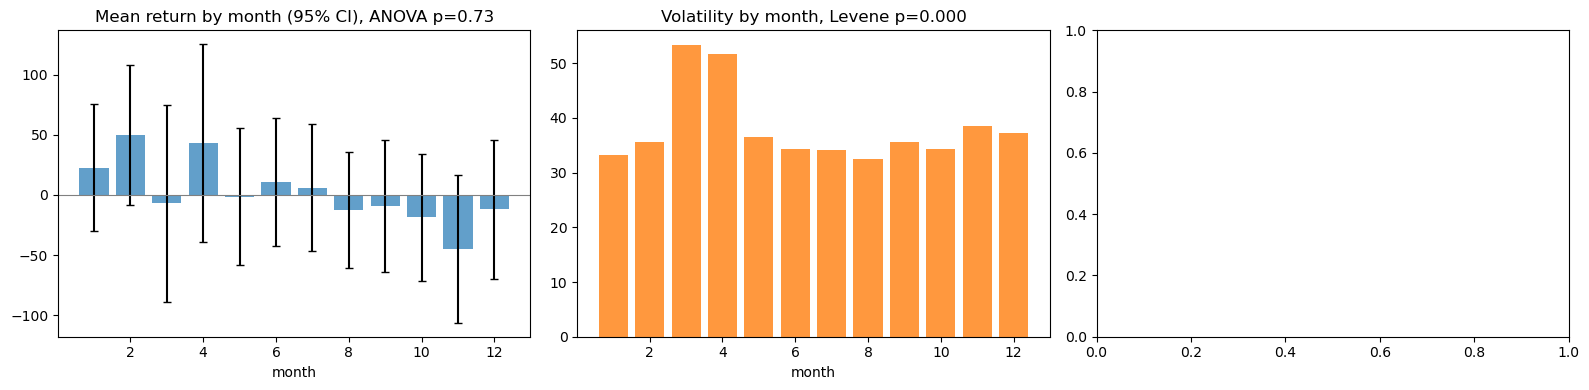

,1,2,3,4,5,6,7,8,9,10,11,12
ann_mean_%,22.80,50.01,-6.89,43.12,-1.44,10.88,6.10,-12.33,-9.36,-18.68,-44.98,-12.05
ann_vol_%,33.24,35.67,53.34,51.64,36.54,34.41,34.08,32.53,35.53,34.33,38.53,37.16
n,382.00,363.00,412.00,382.00,398.00,401.00,400.00,438.00,403.00,413.00,382.00,397.00


In [8]:
pre_lp = logp.loc[:TS - pd.Timedelta(days=1)]
r_pre = pre_lp.diff().dropna()
mon = r_pre.index.month
groups = [r_pre[mon == k].to_numpy() for k in range(1, 13)]
F_stat, F_p = stats.f_oneway(*groups)
L_stat, L_p = stats.levene(*groups, center="median")
season_tab = pd.DataFrame({
    "ann_mean_%": [252 * 100 * g.mean() for g in groups],
    "ann_vol_%": [np.sqrt(252) * 100 * g.std() for g in groups],
    "n": [len(g) for g in groups]}, index=range(1, 13))
print(f"ANOVA equal monthly means:     F={F_stat:.2f}  p={F_p:.3f}")
print(f"Levene equal monthly variances: W={L_stat:.2f}  p={L_p:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ci = [1.96 * 252 * 100 * g.std() / np.sqrt(len(g)) for g in groups]
axes[0].bar(season_tab.index, season_tab["ann_mean_%"], yerr=ci, color="tab:blue", alpha=0.7, capsize=3)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_title(f"Mean return by month (95% CI), ANOVA p={F_p:.2f}"); axes[0].set_xlabel("month")
axes[1].bar(season_tab.index, season_tab["ann_vol_%"], color="tab:orange", alpha=0.8)
axes[1].set_title(f"Volatility by month, Levene p={L_p:.3f}"); axes[1].set_xlabel("month")

if "crude_stocks" in weekly:
    ls = _safe_log(weekly["crude_stocks"][0])
    ls = ls.loc[ls.index >= "2005-01-01"]
    yy, ww = _iso(ls.index)
    dev = pd.Series(ls.to_numpy() - ls.groupby(yy).transform("mean").to_numpy(), index=ls.index)
    prof = pd.DataFrame({"w": ww, "y": yy, "d": dev.to_numpy()})
    hist = prof[prof.y < TS.year].groupby("w")["d"]
    axes[2].fill_between(range(1, 53), 100 * hist.quantile(0.1), 100 * hist.quantile(0.9),
                         alpha=0.25, label="10-90% range")
    axes[2].plot(range(1, 53), 100 * hist.mean(), label="average")
    last = prof[prof.y == prof.y.max()]
    axes[2].plot(last.w, 100 * last.d, color="black", lw=1.2, label=f"{prof.y.max()}")
    axes[2].set_title("US crude stocks: % deviation from the yearly mean")
    axes[2].set_xlabel("ISO week"); axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "seasonality.png", dpi=150); plt.show()
season_tab.round(2).T

## 5. PCA: how many independent factors are in the predictors?

Descriptive analysis on the pre-test sample (from 2010, columns with at most 5% missing). It uses later data, so it is **not** used for forecasting. The forecasting models in section 8 redo PCA inside each rolling window. The number of factors is chosen with the Bai & Ng (2002) IC_p2 criterion.

71 variables, 4024 days. Bai-Ng IC_p2 picks k = 7. First 5 PCs explain 36.7% of variance.


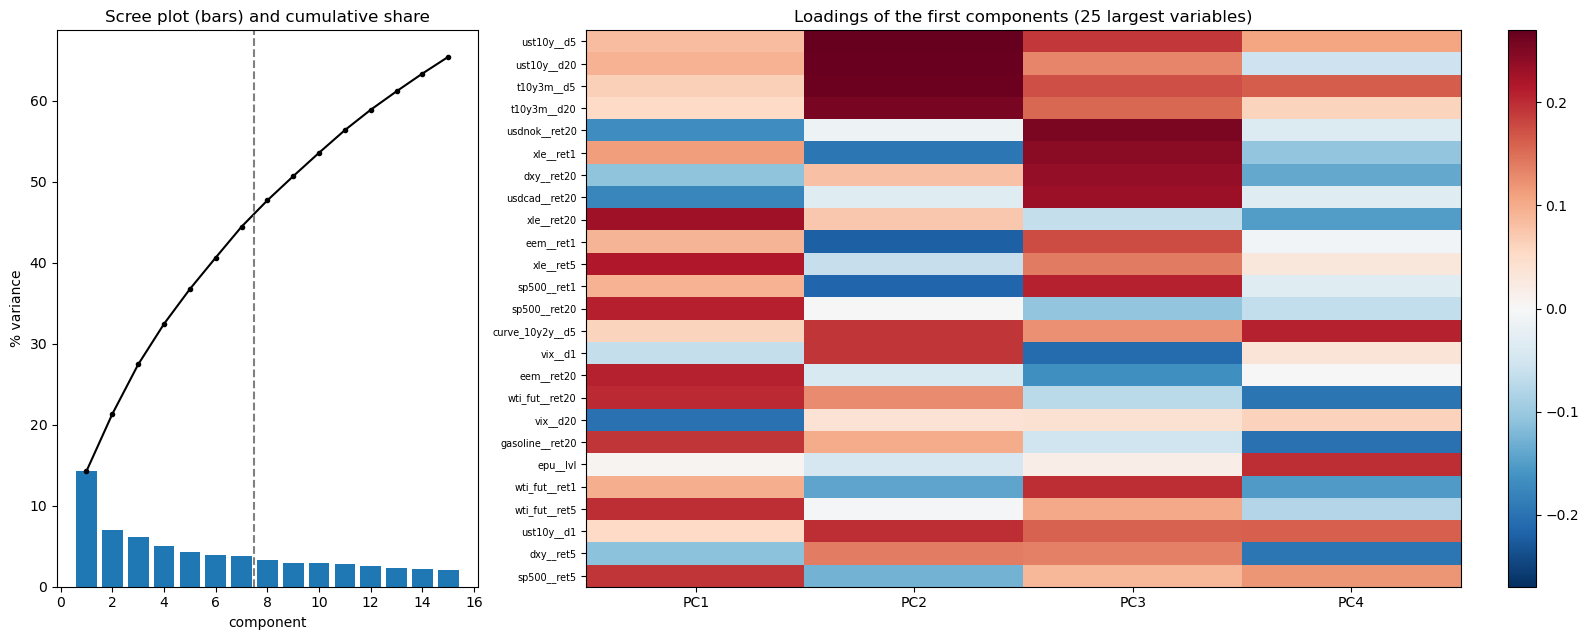

,PC1,PC2,PC3,PC4
ust10y__d5,0.08,0.27,0.19,0.11
ust10y__d20,0.09,0.27,0.13,-0.06
t10y3m__d5,0.06,0.26,0.17,0.16
t10y3m__d20,0.05,0.26,0.15,0.06
usdnok__ret20,-0.17,-0.01,0.25,-0.04
xle__ret1,0.11,-0.20,0.24,-0.11
dxy__ret20,-0.11,0.08,0.24,-0.14
usdcad__ret20,-0.18,-0.03,0.23,-0.03
xle__ret20,0.23,0.07,-0.06,-0.15
eem__ret1,0.09,-0.22,0.18,-0.01


In [9]:
def bai_ng_k(S, N, T, kmax):
    ev = S ** 2
    tot = ev.sum()
    ic = [np.log(max(tot - ev[:k].sum(), 1e-12) / (N * T)) + k * (N + T) / (N * T) * np.log(min(N, T))
          for k in range(1, kmax + 1)]
    return int(np.argmin(ic)) + 1

diag_cols = [c for c in base_cols(X) if not c.startswith(("own_", "season_"))]
D = X.loc["2010-01-01":TS - pd.Timedelta(days=1), diag_cols]
D = D.loc[:, D.isna().mean() <= 0.05].dropna()
Zd = ((D - D.mean()) / D.std()).to_numpy()
U, S, Vt = np.linalg.svd(Zd, full_matrices=False)
evr = S ** 2 / (S ** 2).sum()
k_ic = bai_ng_k(S, Zd.shape[1], Zd.shape[0], cfg.pca_kmax)
print(f"{Zd.shape[1]} variables, {Zd.shape[0]} days. Bai-Ng IC_p2 picks k = {k_ic}. "
      f"First 5 PCs explain {100 * evr[:5].sum():.1f}% of variance.")

K_SHOW = 4
load = pd.DataFrame(Vt[:K_SHOW].T, index=D.columns, columns=[f"PC{i+1}" for i in range(K_SHOW)])
load = load * np.sign(load.loc[load.abs().idxmax()].to_numpy().diagonal())   # largest loading positive
top = load.abs().max(axis=1).sort_values(ascending=False).index[:25]

fig = plt.figure(figsize=(16, 6.5))
ax1 = fig.add_subplot(1, 3, 1)
ax1.bar(range(1, 16), 100 * evr[:15]); ax1.plot(range(1, 16), 100 * np.cumsum(evr[:15]), color="black", marker=".")
ax1.axvline(k_ic + 0.5, color="grey", ls="--"); ax1.set_xlabel("component"); ax1.set_ylabel("% variance")
ax1.set_title("Scree plot (bars) and cumulative share")
ax2 = fig.add_subplot(1, 3, (2, 3))
v = np.abs(load.loc[top].to_numpy()).max()
im = ax2.imshow(load.loc[top].to_numpy(), cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax2.set_yticks(range(len(top))); ax2.set_yticklabels(top, fontsize=7)
ax2.set_xticks(range(K_SHOW)); ax2.set_xticklabels(load.columns)
ax2.set_title("Loadings of the first components (25 largest variables)")
fig.colorbar(im, ax=ax2, fraction=0.03)
fig.tight_layout(); fig.savefig(OUT / "pca_diagnostic.png", dpi=150); plt.show()
load.loc[top].round(2)

## 6. Regime identification: real-time Gaussian HMM

A 2-state Gaussian hidden Markov model on daily Brent returns (Hamilton-type switching mean and variance). States are ordered by variance, so the last state is "turbulent".

- **Expanding window**, re-estimated every `hmm_refit` days with a warm start, so states keep their meaning over time.
- Between re-estimations the **filtered** probability is updated every day with fixed parameters. The filtered probability at `t` uses data up to `t` only. Smoothed probabilities would use later data and are never used here.
- `regime_p` (filtered probability of the turbulent state) becomes a feature, and drives the regime-dependent model and combination below.

In [10]:
class GaussHMM:
    # Gaussian HMM with diagonal covariances, fitted by EM (Baum-Welch) with scaling.
    # tied_mean=True: states share one mean and differ only in variance (volatility regimes).
    # This avoids the common degenerate solution where one state captures a few large moves.
    def __init__(self, k=2, tied_mean=True, max_iter=200, tol=1e-7, var_floor=0.02):
        self.k, self.tied, self.max_iter, self.tol, self.var_floor = k, tied_mean, max_iter, tol, var_floor

    def _init(self, X):
        # data-driven start: split days by 20-day rolling volatility of the first input
        k = self.k
        s = pd.Series(X[:, 0]).rolling(20, min_periods=5).std().bfill().to_numpy()
        lab = np.digitize(s, np.quantile(s, np.linspace(0, 1, k + 1)[1:-1]))
        self.mu = np.vstack([X[lab == j].mean(0) for j in range(k)])
        if self.tied:
            self.mu[:] = X.mean(0)
        self.var = np.vstack([X[lab == j].var(0) for j in range(k)])
        cnt = np.ones((k, k)) + np.histogram2d(lab[:-1], lab[1:], bins=[np.arange(k + 1)] * 2)[0]
        self.A = cnt / cnt.sum(1, keepdims=True)
        self.pi = np.bincount(lab, minlength=k) / len(lab)

    def _B(self, X):
        logB = -0.5 * (((X[:, None, :] - self.mu[None]) ** 2) / self.var[None]
                       + np.log(2 * np.pi * self.var[None])).sum(2)
        c = logB.max(1, keepdims=True)
        return np.exp(logB - c), c.sum()

    def _forward(self, B, pi):
        T, A = len(B), self.A
        alpha, scale = np.empty_like(B), np.empty(T)
        a = pi * B[0]; scale[0] = a.sum(); alpha[0] = a / scale[0]
        for t in range(1, T):
            a = (alpha[t - 1] @ A) * B[t]
            s = a.sum(); scale[t] = s; alpha[t] = a / s
        return alpha, scale

    def _backward(self, B, scale):
        T, A = len(B), self.A
        beta = np.ones_like(B)
        for t in range(T - 2, -1, -1):
            beta[t] = (A @ (B[t + 1] * beta[t + 1])) / scale[t + 1]
        return beta

    def _em(self, X):
        floor = self.var_floor * X.var(0)
        prev, ll = -np.inf, -np.inf
        for _ in range(self.max_iter):
            B, c = self._B(X)
            alpha, scale = self._forward(B, self.pi)
            ll = np.log(scale).sum() + c
            beta = self._backward(B, scale)
            gamma = alpha * beta
            gamma /= gamma.sum(1, keepdims=True)
            xi = (alpha[:-1].T @ (B[1:] * beta[1:] / scale[1:, None])) * self.A
            self.A = xi / xi.sum(1, keepdims=True)
            self.pi = gamma[0]
            w = gamma.sum(0)
            self.mu = (gamma.T @ X) / w[:, None]
            if self.tied:
                self.mu[:] = X.mean(0)
            self.var = np.maximum((gamma.T @ X ** 2) / w[:, None] - self.mu ** 2, floor)
            if ll - prev < self.tol * abs(ll):
                break
            prev = ll
        self.loglik, self.occupancy = ll, gamma.mean(0)
        return self

    def _copy(self):
        return {k: getattr(self, k).copy() for k in ("mu", "var", "A", "pi")}

    def fit(self, X, warm=None):
        cands = []
        if warm is not None:                          # warm start keeps state meanings stable
            for k_ in ("mu", "var", "A", "pi"):
                setattr(self, k_, getattr(warm, k_).copy())
            self._em(X); cands.append((self.loglik, self.occupancy.min(), self._copy()))
        if warm is None or cands[0][1] < 0.03:        # cold start if no warm start or degenerate
            self._init(X); self._em(X); cands.append((self.loglik, self.occupancy.min(), self._copy()))
        ok = [c for c in cands if c[1] >= 0.03] or cands
        best = max(ok, key=lambda c: c[0])
        for k_, v in best[2].items():
            setattr(self, k_, v)
        self.loglik = best[0]
        order = np.argsort(self.var[:, 0])            # last state = highest variance of first input
        self.mu, self.var, self.pi = self.mu[order], self.var[order], self.pi[order]
        self.A = self.A[order][:, order]
        return self

    def filter(self, X):
        B, _ = self._B(X)
        return self._forward(B, self.pi)[0]

def hmm_inputs(logp, names):
    r = logp.diff() * 100
    cols = {"ret": r, "absret5": r.abs().rolling(5).mean(), "logrv20": np.log(r.rolling(20).std())}
    return pd.DataFrame({n: cols[n] for n in names})

def run_regime_id(logp, cfg, verbose=True):
    H = hmm_inputs(logp, cfg.hmm_inputs).dropna()
    vals, idx = H.to_numpy(), H.index
    P = pd.DataFrame(np.nan, index=logp.index, columns=[f"state{k}" for k in range(cfg.hmm_k)])
    log, model, t0 = [], None, time.time()
    i = cfg.hmm_min_obs - 1
    while i < len(vals):
        end = min(i + cfg.hmm_refit, len(vals))
        lo = 0 if cfg.hmm_window is None else max(0, i + 1 - cfg.hmm_window)
        model = GaussHMM(cfg.hmm_k).fit(vals[lo:i + 1], warm=model)     # data up to i only
        alpha = model.filter(vals[lo:end])                              # row t uses data <= t
        P.loc[idx[i:end]] = alpha[i - lo:]
        log.append({"date": idx[i], "pos": logp.index.get_loc(idx[i]), "A": model.A.copy(),
                    "mu": model.mu.copy(), "var": model.var.copy()})
        i = end
    if verbose:
        print(f"[hmm] {len(log)} re-estimations ({time.time() - t0:.0f}s)")
    return P, log

def add_regime_features(X, P, cfg):
    X = X.copy()
    X["regime_p"] = P.iloc[:, -1].reindex(X.index)
    for c in base_cols(X):
        if not c.startswith("season_") and any(s in c for s in cfg.rs_patterns):
            X[f"rs__{c}"] = X[c] * X["regime_p"]
    return X

[hmm] 68 re-estimations (15s)
latest HMM fit: 2026-07-21


,ann_mean_ret_%,ann_vol_%,stay_prob,expected_duration_days,share_of_days_%
state0,0.98,24.953,0.981,51.938,78.424
state1,0.98,69.052,0.927,13.646,21.576


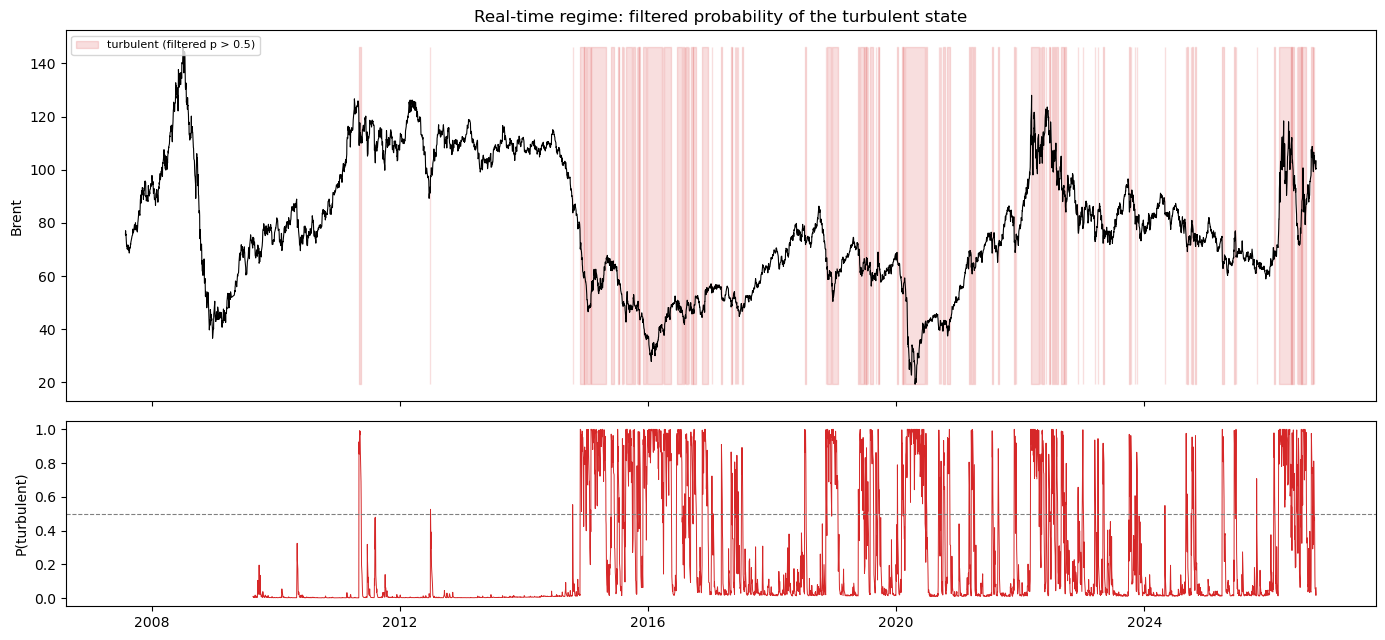

In [11]:
P_reg, hmm_log = run_regime_id(logp, cfg)
X = add_regime_features(X, P_reg, cfg)
regime_label = pd.Series(np.where(X["regime_p"] > 0.5, "turbulent", "calm"), index=X.index).where(X["regime_p"].notna())

last = hmm_log[-1]
reg_tab = pd.DataFrame({
    "ann_mean_ret_%": 252 * last["mu"][:, 0],
    "ann_vol_%": np.sqrt(252 * last["var"][:, 0]),
    "stay_prob": np.diag(last["A"]),
    "expected_duration_days": 1 / (1 - np.diag(last["A"])),
    "share_of_days_%": 100 * P_reg.dropna().idxmax(axis=1).value_counts(normalize=True).reindex(P_reg.columns).fillna(0).to_numpy(),
}, index=P_reg.columns)
print(f"latest HMM fit: {last['date'].date()}")
display(reg_tab.round(3))

price = np.exp(logp)
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(price.index, price, color="black", lw=0.8)
turb = (X["regime_p"] > 0.5).reindex(price.index).fillna(False).to_numpy()
axes[0].fill_between(price.index, price.min(), price.max(), where=turb, color="tab:red", alpha=0.15,
                     step="post", label="turbulent (filtered p > 0.5)")
axes[0].set_ylabel("Brent"); axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_title("Real-time regime: filtered probability of the turbulent state")
axes[1].plot(X.index, X["regime_p"], color="tab:red", lw=0.7)
axes[1].axhline(0.5, color="grey", ls="--", lw=0.8); axes[1].set_ylabel("P(turbulent)")
fig.tight_layout(); fig.savefig(OUT / "regime_identification.png", dpi=150); plt.show()

## 7. Regime prediction from macro variables

Will Brent be in the turbulent regime `h` days from now? Four forecasts of `P(turbulent at t+h)`:

| Forecast | Information |
|---|---|
| `p_clim` | share of turbulent days in the training window |
| `p_now` | today's filtered probability ("the regime persists") |
| `p_markov` | HMM transition matrix only: `p_t · A^h` |
| `p_logit` | logistic regression on the current regime probability plus macro, oil-market and calendar variables |

`p_logit` is a two-step version of a Markov-switching model with time-varying transition probabilities (Filardo 1994; Diebold, Lee & Weinbach 1994). It is estimated on the same rolling window and refit schedule as the price models. Labels are the real-time regime at `t+h`, so training only uses labels observed by `t`. Scored with the Brier score, Brier skill score vs climatology, and AUC.

In [12]:
REGIME_FEATURES = ["regime_p", "own_rv20", "ovx__lvl", "vix__lvl", "epu__lvl", "t10y3m__lvl",
                   "curve_10y2y__lvl", "wei__lvl", "inv__anom", "wti_slope__lvl", "crack321__anom",
                   "season_sin1", "season_cos1"]

def run_regime_pred(X, P, hmm_log, cfg, verbose=True):
    feats = [c for c in REGIME_FEATURES if c in X.columns]
    p_turb = P.iloc[:, -1].reindex(X.index)
    lab = (p_turb > 0.5).astype(float).where(p_turb.notna())
    Pm = P.reindex(X.index).to_numpy()
    log_pos = np.array([e["pos"] for e in hmm_log])
    dates = X.index
    start, last = dates.searchsorted(pd.Timestamp(cfg.oos_start)), len(dates) - 1
    rows, t0 = [], time.time()
    for h in cfg.horizons:
        lab_f = lab.shift(-h)
        mdl = None
        for k, i in enumerate(range(start, last + 1)):
            if k % cfg.refit_every == 0 or mdl is None or i == last:
                tr = train_rows(i, h, cfg.window)
                Z = X.iloc[tr][feats]
                Z = Z.loc[:, Z.isna().mean() <= 0.05]
                yv = lab_f.iloc[tr]
                ok = Z.notna().all(axis=1) & yv.notna()
                clim = float(yv[ok].mean()) if ok.any() else np.nan
                if ok.sum() < 200 or yv[ok].nunique() < 2:
                    mdl = ("clim", clim)
                else:
                    mu, sd = Z[ok].mean(), Z[ok].std().replace(0, 1)
                    lr = LogisticRegression(C=cfg.regime_C, max_iter=2000)
                    lr.fit(((Z[ok] - mu) / sd).to_numpy(), yv[ok].to_numpy())
                    mdl = ("logit", list(Z.columns), mu, sd, lr, clim)
            if mdl[0] == "logit":
                _, cols, mu, sd, lr, clim = mdl
                z = ((X.iloc[i][cols] - mu) / sd).fillna(0.0).to_numpy()[None, :]
                p_logit = float(lr.predict_proba(z)[0, 1])
            else:
                clim = mdl[1]; p_logit = clim
            a = np.searchsorted(log_pos, i, side="right") - 1
            p_i = Pm[i]
            p_markov = (float((p_i @ matrix_power(hmm_log[a]["A"], h))[-1])
                        if a >= 0 and np.isfinite(p_i).all() else np.nan)
            rows.append({"date": dates[i], "h": h, "p_clim": clim, "p_now": p_i[-1],
                         "p_markov": p_markov, "p_logit": p_logit, "actual": lab_f.iloc[i]})
    if verbose:
        print(f"[regime-pred] done ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)

def regime_scores(rp, cols=("p_clim", "p_now", "p_markov", "p_logit")):
    rows = []
    for h, g in rp.dropna(subset=["actual"]).groupby("h"):
        y = g["actual"].to_numpy()
        bs_clim = np.mean((g["p_clim"].to_numpy() - y) ** 2)
        for c in cols:
            p = g[c].to_numpy()
            ok = np.isfinite(p)
            bs = np.mean((p[ok] - y[ok]) ** 2)
            auc = roc_auc_score(y[ok], p[ok]) if len(np.unique(y[ok])) == 2 else np.nan
            rows.append({"h": h, "forecast": c, "n": int(ok.sum()), "base_rate": y.mean(),
                         "Brier": bs, "BSS_vs_clim": 1 - bs / bs_clim if bs_clim > 0 else np.nan,
                         "AUC": auc})
    return pd.DataFrame(rows)

## 8. Price forecasting models

All models predict the h-day log return; the price forecast is `P(t)·exp(ŷ)`. Direct multi-step forecasts.

| Model | Description |
|---|---|
| `RW` | No-change forecast |
| `HistMean` | Mean h-day return in the window |
| `AR_direct` | OLS on own 1/5/20-day returns |
| `KitchenSink` | OLS on all base features |
| `LASSO` | LASSO on all base features; penalty at the minimum of blocked CV (gap = h), as in the paper |
| `LASSO_1se` | Same, with the one-standard-error rule: the largest penalty within 1 SE of the CV minimum (more conservative) |
| `PCA_reg` | Diffusion index (Stock & Watson 2002): factors from PCA of non-own features in the window, k by Bai–Ng IC_p2, plus own lags |
| `TPCA` | Targeted PCA (Bai & Ng 2008): keep features with HAC \|t\| > 1.65 in univariate regressions on the window, then PCA |
| `LASSO_RS` | LASSO (CV minimum) with the regime probability and its interactions with level, anomaly and 20-day features: regime-dependent slopes |

By default (`fit_intercept=False`) the regression models have no intercept: with all slopes at zero they reduce to the no-change forecast rather than to the window-mean return. `HistMean` stays as a separate benchmark.

Section 9 adds two combinations: `Combo_EW` (equal weights over the combination pool) and `Combo_Regime` (inverse-MSE weights estimated separately for days with the same predicted regime).

In [13]:
AR_COLS = ["own_ret1", "own_ret5", "own_ret20"]
ALL_MODELS = ["RW", "HistMean", "AR_direct", "KitchenSink", "LASSO", "LASSO_1se", "PCA_reg", "TPCA", "LASSO_RS"]

@dataclass
class Fit:
    cols: list
    mu: np.ndarray
    sd: np.ndarray
    coef: np.ndarray
    intercept: float
    selected: list = field(default_factory=list)
    info: dict = field(default_factory=dict)

    def predict(self, x):
        # x: pandas Series of today's features
        if not self.cols:
            return self.intercept
        return self._apply(x[self.cols].to_numpy(dtype=float))

    def predict_row(self, row, columns):
        # row: numpy array aligned with `columns` (faster inside the backtest loop)
        if not self.cols:
            return self.intercept
        if getattr(self, "_pos", None) is None:
            self._pos = columns.get_indexer(self.cols)
        return self._apply(row[self._pos])

    def _apply(self, v):
        z = (v - self.mu) / self.sd
        z = np.where(np.isfinite(z), z, 0.0)          # missing today -> window mean
        return float(self.intercept + z @ self.coef)

_E = np.array([])

def _prep(X, y, cols=None, max_nan=0.05):
    # window data -> standardized matrix; columns screened on window data only
    df = X if cols is None else X[cols]
    A, yv, names = df.to_numpy(dtype=float), y.to_numpy(dtype=float), np.array(df.columns)
    ok = np.isfinite(yv)
    A, yv = A[ok], yv[ok]
    if cols is None:
        with np.errstate(invalid="ignore"):
            keep = (np.isnan(A).mean(0) <= max_nan) & (np.nan_to_num(np.nanstd(A, 0)) > 0)
        A, names = A[:, keep], names[keep]
    rows = np.isfinite(A).all(axis=1)
    A, yv = A[rows], yv[rows]
    mu, sd = A.mean(0), A.std(0, ddof=1)
    sd = np.where(sd > 0, sd, 1.0)
    return list(names), (A - mu) / sd, yv, mu, sd

def _ols(cols, Z, y, mu, sd, intercept=True):
    if Z.shape[1] == 0:
        return Fit([], mu, sd, _E, float(np.mean(y)) if intercept else 0.0)
    if not intercept:
        beta, *_ = np.linalg.lstsq(Z, y, rcond=None)
        return Fit(cols, mu, sd, beta, 0.0, selected=list(cols))
    beta, *_ = np.linalg.lstsq(np.column_stack([np.ones(len(y)), Z]), y, rcond=None)
    return Fit(cols, mu, sd, beta[1:], float(beta[0]), selected=list(cols))

def fit_rw(X, y, h, cfg, ctx):
    return Fit([], _E, _E, _E, 0.0)

def fit_histmean(X, y, h, cfg, ctx):
    return Fit([], _E, _E, _E, float(y.dropna().mean()))

def fit_ar(X, y, h, cfg, ctx):
    return _ols(*_prep(X, y, [c for c in AR_COLS if c in X.columns]), intercept=cfg.fit_intercept)

def fit_kitchen(X, y, h, cfg, ctx):
    return _ols(*_prep(X[base_cols(X)], y), intercept=cfg.fit_intercept)

def _make_lassocv(cfg, cv):
    kw = dict(cv=cv, eps=cfg.lasso_eps, max_iter=5000, tol=1e-3, fit_intercept=cfg.fit_intercept,
              random_state=cfg.seed)
    if "n_alphas" in inspect.signature(LassoCV).parameters:      # older sklearn
        return LassoCV(n_alphas=cfg.n_alphas, **kw)
    return LassoCV(alphas=cfg.n_alphas, **kw)

def _lasso(Xw, y, h, cfg, rule="min", ctx=None):
    # the CV path is shared by LASSO and LASSO_1se on the same window (cached in ctx)
    key = (Xw.index[0], Xw.index[-1], Xw.shape[1])
    cache = ctx.get("lasso_cv") if ctx is not None else None
    if cache is not None and cache[0] == key:
        _, cols, Z, yv, mu, sd, m = cache
    else:
        cols, Z, yv, mu, sd = _prep(Xw, y)
        m = _make_lassocv(cfg, TimeSeriesSplit(n_splits=cfg.cv_folds, gap=h)).fit(Z, yv)
        if ctx is not None:
            ctx["lasso_cv"] = (key, cols, Z, yv, mu, sd, m)
    coef, icpt, alpha = m.coef_, float(m.intercept_), float(m.alpha_)
    if rule == "1se":
        mse = m.mse_path_.mean(axis=1)
        se = m.mse_path_.std(axis=1) / np.sqrt(m.mse_path_.shape[1])
        j = int(np.argmin(mse))
        a1 = float(m.alphas_[mse <= mse[j] + se[j]].max())      # largest alpha within 1 SE
        if a1 > alpha:
            lm = Lasso(alpha=a1, max_iter=5000, tol=1e-3, fit_intercept=cfg.fit_intercept).fit(Z, yv)
            coef, icpt, alpha = lm.coef_, float(lm.intercept_), a1
    sel = [c for c, b in zip(cols, coef) if abs(b) > 1e-12]
    return Fit(cols, mu, sd, coef, icpt, selected=sel,
               info={"alpha": alpha, "n_selected": len(sel), "n_candidates": len(cols)})

def fit_lasso(X, y, h, cfg, ctx):
    return _lasso(X[base_cols(X)], y, h, cfg, "min", ctx)

def fit_lasso_1se(X, y, h, cfg, ctx):
    return _lasso(X[base_cols(X)], y, h, cfg, "1se", ctx)

def fit_lasso_rs(X, y, h, cfg, ctx):
    if "regime_p" not in X.columns:
        return fit_lasso(X, y, h, cfg, ctx)
    return _lasso(X, y, h, cfg)

def _factor_fit(cols, Z, yv, mu, sd, fac_idx, own_idx, cfg, extra_info=None):
    # regress y on PCA factors of Z[:, fac_idx] plus Z[:, own_idx]; map back to a linear rule in Z
    Zf = Z[:, fac_idx]
    _, S, Vt = np.linalg.svd(Zf, full_matrices=False)
    kmax = max(1, min(cfg.pca_kmax, Zf.shape[1] - 1))
    k = cfg.pca_k or bai_ng_k(S, Zf.shape[1], Zf.shape[0], kmax)
    V = Vt[:k].T
    D = np.column_stack([Zf @ V, Z[:, own_idx]])
    if cfg.fit_intercept:
        D = np.column_stack([np.ones(len(yv)), D])
    beta, *_ = np.linalg.lstsq(D, yv, rcond=None)
    icpt, beta = (float(beta[0]), beta[1:]) if cfg.fit_intercept else (0.0, beta)
    coef = np.zeros(len(cols))
    coef[fac_idx] += V @ beta[:k]
    coef[own_idx] += beta[k:]
    info = {"k": k, **(extra_info or {})}
    return Fit(cols, mu, sd, coef, icpt, info=info)

def fit_pca(X, y, h, cfg, ctx):
    cols, Z, yv, mu, sd = _prep(X[base_cols(X)], y)
    fac = [i for i, c in enumerate(cols) if not c.startswith(("own_", "season_"))]
    own = [i for i, c in enumerate(cols) if c in AR_COLS]
    if len(fac) < 3:
        return fit_histmean(X, y, h, cfg, ctx)
    return _factor_fit(cols, Z, yv, mu, sd, fac, own, cfg)

def _hac_t(Zf, yv, h):
    # t-statistics of univariate slopes with Newey-West variance (lag h-1)
    yc = yv - yv.mean()
    sxx = (Zf ** 2).sum(0)
    b = Zf.T @ yc / sxx
    g = Zf * (yc[:, None] - Zf * b)
    T, L = len(yc), max(h - 1, 0)
    S = (g * g).sum(0) / T
    for l in range(1, L + 1):
        S = S + 2 * (1 - l / (L + 1)) * (g[l:] * g[:-l]).sum(0) / T
    return b / np.sqrt(np.maximum(T * S, 1e-18) / sxx ** 2)

def fit_tpca(X, y, h, cfg, ctx):
    cols, Z, yv, mu, sd = _prep(X[base_cols(X)], y)
    fac = np.array([i for i, c in enumerate(cols) if not c.startswith(("own_", "season_"))])
    own = [i for i, c in enumerate(cols) if c in AR_COLS]
    if len(fac) == 0:
        return fit_histmean(X, y, h, cfg, ctx)
    t = _hac_t(Z[:, fac], yv, h)
    keep = fac[np.abs(t) > cfg.tpca_t]
    if len(keep) == 0:
        f = fit_histmean(X, y, h, cfg, ctx) if cfg.fit_intercept else fit_rw(X, y, h, cfg, ctx)
        f.info = {"k": 0, "n_targeted": 0}
        return f
    if len(keep) <= 2:                       # too few for PCA: plain OLS on them
        idx = list(keep) + own
        f = _ols([cols[i] for i in idx], Z[:, idx], yv, mu[idx], sd[idx], intercept=cfg.fit_intercept)
        f.info = {"k": len(keep), "n_targeted": len(keep)}
        return f
    return _factor_fit(cols, Z, yv, mu, sd, list(keep), own, cfg, {"n_targeted": len(keep)})

FITTERS = {"RW": fit_rw, "HistMean": fit_histmean, "AR_direct": fit_ar, "KitchenSink": fit_kitchen,
           "LASSO": fit_lasso, "LASSO_1se": fit_lasso_1se, "PCA_reg": fit_pca, "TPCA": fit_tpca,
           "LASSO_RS": fit_lasso_rs}

## 9. Rolling backtest and forecast combination

One loop serves the pseudo-OOS backtest and the live update: at each origin, models see data up to that day only.

`Combo_Regime`: for origin `t`, take past forecasts whose outcomes are already known (origins `s ≤ t − h`, within `combo_lookback` days) and that had the same **predicted** regime for their target date (`p_logit > 0.5`). Weights are inverse MSE over that subset (Bates–Granger), shrunk halfway to equal weights. If fewer than `combo_min_obs` such forecasts exist, all past forecasts are used.

In [14]:
def run_backtest(X, Y, logp, cfg, verbose=True):
    models = cfg.model_list or ALL_MODELS
    dates = X.index
    start, last = dates.searchsorted(pd.Timestamp(cfg.oos_start)), len(dates) - 1
    Xv, rp_pos = X.to_numpy(dtype=float), X.columns.get_indexer(["regime_p"])[0]
    fc_rows, sel_rows, info_rows, t0 = [], [], [], time.time()
    for h in cfg.horizons:
        y, ctx, fits = Y[h], {}, {}
        for k, i in enumerate(range(start, last + 1)):
            if k % cfg.refit_every == 0 or i == last or not fits:
                rows = train_rows(i, h, cfg.window)
                if len(rows) < 0.8 * cfg.window:
                    continue
                Xtr, ytr = X.iloc[rows], y.iloc[rows]
                for m in models:
                    fits[m] = FITTERS[m](Xtr, ytr, h, cfg, ctx)
                    if fits[m].info:
                        info_rows.append({"h": h, "date": dates[i], "model": m, **fits[m].info})
                lf = fits.get("LASSO")
                if lf is not None:
                    sel_rows.append({"h": h, "date": dates[i],
                                     **{c: b for c, b in zip(lf.cols, lf.coef) if abs(b) > 1e-12}})
            xi = Xv[i]
            rec = {"date": dates[i], "h": h,
                   "target_date": dates[i + h] if i + h <= last else pd.NaT,
                   "logp": logp.iloc[i], "y": y.iloc[i],
                   "regime_p": xi[rp_pos] if rp_pos >= 0 else np.nan}
            for m in models:
                rec[m] = fits[m].predict_row(xi, X.columns)
            fc_rows.append(rec)
        if verbose:
            print(f"[backtest] h={h:>2} done ({time.time() - t0:.0f}s)")
    fc = pd.DataFrame(fc_rows)
    fc["P_t"] = np.exp(fc["logp"])
    fc["P_true"] = np.exp(fc["logp"] + fc["y"])     # NaN where not yet observed
    return fc, pd.DataFrame(sel_rows), pd.DataFrame(info_rows), models

def add_combinations(fc, rp, cfg):
    fc = fc.copy()
    pool = [m for m in cfg.combo_pool if m in fc.columns]
    fc["Combo_EW"] = fc[pool].mean(axis=1)
    if rp is not None and len(rp):
        fc = fc.drop(columns=["p_logit"], errors="ignore").merge(
            rp[["date", "h", "p_logit"]], on=["date", "h"], how="left")
    else:
        fc["p_logit"] = np.nan
    fc["pred_turb"] = fc["p_logit"].fillna(fc["regime_p"]).fillna(0) > 0.5
    fc["Combo_Regime"] = np.nan
    eq = np.full(len(pool), 1.0 / len(pool))
    for h, g in fc.groupby("h"):
        g = g.sort_values("date")
        F = g[pool].to_numpy()
        e2 = (g["y"].to_numpy()[:, None] - F) ** 2
        b = g["pred_turb"].to_numpy()
        out = np.empty(len(g))
        for t in range(len(g)):
            hi = t - h                                  # origins whose outcome is known at t
            w = eq
            if hi + 1 >= cfg.combo_min_obs:
                lo = max(0, hi - cfg.combo_lookback + 1)
                E, sel = e2[lo:hi + 1], b[lo:hi + 1] == b[t]
                if sel.sum() >= cfg.combo_min_obs:
                    E = E[sel]
                mse = np.nanmean(E, axis=0)
                if np.all(np.isfinite(mse)) and np.all(mse > 0):
                    w = (1 / mse) / (1 / mse).sum()
                    w = cfg.combo_shrink * eq + (1 - cfg.combo_shrink) * w
            out[t] = F[t] @ w
        fc.loc[g.index, "Combo_Regime"] = out
    return fc

In [15]:
with open(OUT / "config_used.json", "w") as f:
    json.dump(asdict(cfg), f, indent=2, default=str)

rp = run_regime_pred(X, P_reg, hmm_log, cfg)
fc, sel, fit_info, base_models = run_backtest(X, Y, logp, cfg)
fc = add_combinations(fc, rp, cfg)
models = base_models + ["Combo_EW", "Combo_Regime"]

fc.to_csv(OUT / "forecasts.csv", index=False)
rp.to_csv(OUT / "regime_forecasts.csv", index=False)
sel.to_csv(OUT / "lasso_selection_log.csv", index=False)
fit_info.to_csv(OUT / "fit_info_log.csv", index=False)
val, test = fc[fc["date"] < TS], fc[fc["date"] >= TS]
print(f"validation origins: {val['date'].nunique()}   test origins: {test['date'].nunique()}")

[regime-pred] done (15s)
[backtest] h= 1 done (95s)
[backtest] h= 5 done (154s)
[backtest] h=10 done (199s)
[backtest] h=20 done (231s)
[backtest] h=40 done (256s)
[backtest] h=60 done (278s)
validation origins: 2702   test origins: 6


## 10. Regime prediction results

BSS > 0 means better than climatology; AUC 0.5 is no skill. `p_now` is a strong benchmark at short horizons because regimes are persistent; macro variables can only add value if `p_logit` beats `p_now` and `p_markov`, which is most likely at longer horizons.

AUC                         BSS_vs_clim                        
forecast p_clim p_logit p_markov  p_now      p_clim p_logit p_markov  p_now
h                                                                          
1         0.440   0.963    0.964  0.964         0.0   0.740    0.729  0.736
5         0.439   0.839    0.833  0.838         0.0   0.369    0.364  0.305
10        0.436   0.763    0.764  0.777         0.0   0.222    0.240  0.113
20        0.436   0.666    0.696  0.727         0.0   0.054    0.140 -0.021
40        0.436   0.556    0.558  0.630         0.0  -0.156    0.072 -0.224
60        0.442   0.487    0.492  0.536         0.0  -0.319    0.048 -0.452

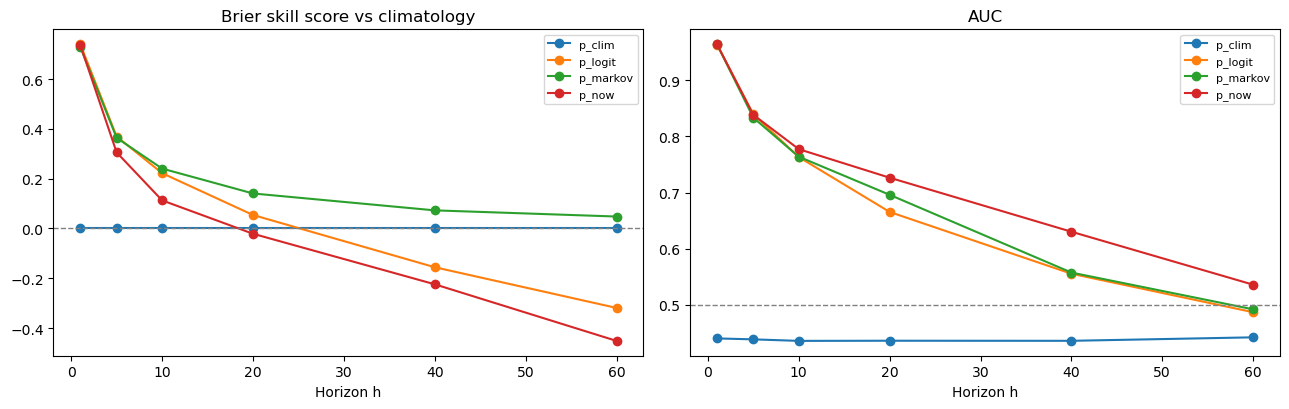

In [16]:
rs = regime_scores(rp[rp["date"] < TS])
rs.to_csv(OUT / "regime_prediction_scores.csv", index=False)
display(rs.pivot_table(index="h", columns="forecast", values=["BSS_vs_clim", "AUC"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for c, g in rs.groupby("forecast"):
    axes[0].plot(g["h"], g["BSS_vs_clim"], marker="o", label=c)
    axes[1].plot(g["h"], g["AUC"], marker="o", label=c)
axes[0].axhline(0, color="grey", ls="--", lw=1); axes[0].set_title("Brier skill score vs climatology")
axes[1].axhline(0.5, color="grey", ls="--", lw=1); axes[1].set_title("AUC")
for ax in axes:
    ax.set_xlabel("Horizon h"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "regime_prediction_scores.png", dpi=150); plt.show()

## 11. Evaluation functions

- **Accuracy:** MAE / RMSE / MAPE on price, RMSE on returns, MSPE ratio and MAE improvement vs RW.
- **Tests:** Diebold–Mariano with HLN correction and Newey–West variance (lag h−1); Clark–West for nested comparisons against RW.
- **Direction:** hit rate, precision / recall / F1 for up moves, Pesaran–Timmermann. With overlapping h-day returns (h > 1) the PT test overstates significance.
- **Economic value:** sign rule on h=1 forecasts with costs.

In [17]:
def nw_var(x, lags):
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    v = x @ x / n
    for L in range(1, min(lags, n - 1) + 1):
        v += 2 * (1 - L / (lags + 1)) * (x[L:] @ x[:-L]) / n
    return max(v, 1e-18) / n

def dm_test(e_bench, e_model, h):
    d = e_bench ** 2 - e_model ** 2
    n = len(d)
    if n < 10:
        return np.nan, np.nan
    stat = d.mean() / np.sqrt(nw_var(d, max(h - 1, 0)))
    stat *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * stats.t.sf(abs(stat), df=n - 1)

def cw_test(y, f_bench, f_model, h):
    adj = (y - f_bench) ** 2 - ((y - f_model) ** 2 - (f_bench - f_model) ** 2)
    if len(adj) < 10:
        return np.nan, np.nan
    stat = adj.mean() / np.sqrt(nw_var(adj, max(h - 1, 0)))
    return stat, stats.norm.sf(stat)

def pt_test(y, f):
    up_y, up_f = (y > 0).astype(float), (f > 0).astype(float)
    n = len(y)
    if n < 10:
        return np.nan, np.nan, np.nan
    p_hat = np.mean(up_y == up_f)
    if up_f.std() == 0:
        return p_hat, np.nan, np.nan
    py, pf = up_y.mean(), up_f.mean()
    p_star = py * pf + (1 - py) * (1 - pf)
    v_hat = p_star * (1 - p_star) / n
    v_star = ((2 * py - 1) ** 2 * pf * (1 - pf) / n + (2 * pf - 1) ** 2 * py * (1 - py) / n
              + 4 * py * pf * (1 - py) * (1 - pf) / n ** 2)
    if v_hat - v_star <= 0:
        return p_hat, np.nan, np.nan
    s = (p_hat - p_star) / np.sqrt(v_hat - v_star)
    return p_hat, s, stats.norm.sf(s)

def _prf(y, f):
    t, p = y > 0, f > 0
    tp = np.sum(t & p)
    prec = tp / p.sum() if p.sum() else np.nan
    rec = tp / t.sum() if t.sum() else np.nan
    f1 = 2 * prec * rec / (prec + rec) if np.isfinite(prec * rec) and prec + rec > 0 else np.nan
    return prec, rec, f1

def evaluate(fc, models, bench="RW"):
    rows = []
    for h, g in fc.dropna(subset=["y"]).groupby("h"):
        y, P0, P1 = g["y"].to_numpy(), g["P_t"].to_numpy(), g["P_true"].to_numpy()
        fb = g[bench].to_numpy()
        e_b = y - fb
        mse_b = np.mean(e_b ** 2)
        mae_b = np.mean(np.abs(P1 - P0 * np.exp(fb)))
        for m in models:
            f = g[m].to_numpy()
            Phat, e = P0 * np.exp(f), y - f
            r = {"h": h, "model": m, "n": len(y),
                 "MAE_price": np.mean(np.abs(P1 - Phat)),
                 "RMSE_price": np.sqrt(np.mean((P1 - Phat) ** 2)),
                 "MAPE_%": 100 * np.mean(np.abs((P1 - Phat) / P1)),
                 "RMSE_ret": np.sqrt(np.mean(e ** 2)),
                 "MSPE_ratio_vs_RW": np.mean(e ** 2) / mse_b,
                 "MAE_impr_vs_RW_%": 100 * (1 - np.mean(np.abs(P1 - Phat)) / mae_b)}
            if m != bench:
                r["DM_stat"], r["DM_p"] = dm_test(e_b, e, h)
                r["CW_stat"], r["CW_p"] = cw_test(y, fb, f, h)
            if m != "RW":
                r["dir_acc"], r["PT_stat"], r["PT_p"] = pt_test(y, f)
                r["precision_up"], r["recall_up"], r["F1_up"] = _prf(y, f)
            rows.append(r)
    return pd.DataFrame(rows)

def by_group(fc, models, key, name):
    d = fc.dropna(subset=["y"]).copy()
    d[name] = d["date"].map(key)
    rows = []
    for (h, gval), g in d.dropna(subset=[name]).groupby(["h", name]):
        y = g["y"].to_numpy()
        mse_b = np.mean((y - g["RW"].to_numpy()) ** 2)
        for m in models:
            f = g[m].to_numpy()
            rows.append({"h": h, name: gval, "model": m, "n": len(y),
                         "MSPE_ratio_vs_RW": np.mean((y - f) ** 2) / mse_b,
                         "dir_acc": np.mean((y > 0) == (f > 0)) if m != "RW" else np.nan})
    return pd.DataFrame(rows)

def trading(fc, models, h, cost_bps):
    g = fc[fc["h"] == h].dropna(subset=["y"]).sort_values("date")
    r = g["y"].to_numpy()
    strategies = {m: np.sign(g[m].to_numpy()) for m in models if m != "RW"}
    strategies["BuyHold"] = np.ones(len(r))
    out, curves, ann = [], {}, 252 / h
    for m, pos in strategies.items():
        turn = np.abs(np.diff(np.concatenate([[0.0], pos])))
        pnl = pos * r - turn * cost_bps / 1e4
        eq = np.cumsum(pnl)
        dd = eq - np.maximum.accumulate(eq)
        out.append({"strategy": m, "ann_log_return_%": 100 * pnl.mean() * ann,
                    "ann_vol_%": 100 * pnl.std() * np.sqrt(ann),
                    "sharpe": pnl.mean() / pnl.std() * np.sqrt(ann) if pnl.std() > 0 else np.nan,
                    "max_drawdown_%": 100 * (np.exp(dd.min()) - 1),
                    "hit_rate": np.mean(pnl[pos != 0] > 0) if (pos != 0).any() else np.nan,
                    "n_position_changes": int((turn > 0).sum()),
                    "total_cost_%": 100 * (turn * cost_bps / 1e4).sum()})
        curves[m] = pd.Series(eq, index=g["date"].to_numpy())
    return pd.DataFrame(out), pd.DataFrame(curves)

## 12. Results: accuracy against the benchmarks

Validation = pseudo out-of-sample from `oos_start` to `test_start`. MSPE ratio below 1 beats the no-change forecast.

In [18]:
ev = evaluate(val, models)
ev.to_csv(OUT / "metrics_validation.csv", index=False)
if test["y"].notna().any():
    evaluate(test, models).to_csv(OUT / "metrics_test.csv", index=False)

display(ev.pivot_table(index="model", columns="h", values="MSPE_ratio_vs_RW").loc[models].round(3))
ev[["h", "model", "MAE_price", "RMSE_price", "MAPE_%", "MSPE_ratio_vs_RW",
    "DM_p", "CW_p", "dir_acc", "PT_p", "F1_up"]].round(4)

h,1,5,10,20,40,60
model,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.001,1.005,1.012,1.026,1.036,1.035
AR_direct,1.008,1.021,1.022,1.015,1.005,0.992
KitchenSink,1.361,1.723,2.186,2.784,3.893,6.352
LASSO,1.000,0.999,1.001,0.998,1.007,1.012
LASSO_1se,1.000,1.000,1.000,1.000,1.000,1.000
PCA_reg,1.033,1.082,1.079,1.030,1.035,1.010
TPCA,1.026,1.134,1.117,1.125,1.127,1.229
LASSO_RS,1.002,1.001,1.007,1.013,1.013,1.006


,h,model,MAE_price,RMSE_price,MAPE_%,MSPE_ratio_vs_RW,DM_p,CW_p,dir_acc,PT_p,F1_up
0,1,RW,1.1917,1.8180,1.7426,1.0000,NaN,NaN,NaN,NaN,NaN
1,1,HistMean,1.1920,1.8188,1.7434,1.0009,0.1466,0.8545,0.5044,0.4467,0.5410
2,1,AR_direct,1.1975,1.8271,1.7498,1.0082,0.2066,0.6037,0.4815,0.9743,0.5016
3,1,KitchenSink,1.4123,2.1187,2.0639,1.3610,0.0000,0.0511,0.5278,0.0037,0.5569
4,1,LASSO,1.1908,1.8195,1.7405,0.9998,0.8623,0.2811,0.4993,0.1051,0.4303
...,...,...,...,...,...,...,...,...,...,...,...
61,60,PCA_reg,9.6540,13.4221,14.6953,1.0101,0.8890,0.0416,0.5816,0.0000,0.5719
62,60,TPCA,11.0008,14.7139,16.8353,1.2290,0.0221,0.1579,0.5170,0.0079,0.5025
63,60,LASSO_RS,9.0118,12.7629,14.1488,1.0063,0.6189,0.1761,0.5476,0.0000,0.4661
64,60,Combo_EW,8.9262,12.7259,13.9308,0.9670,0.4547,0.0930,0.5449,0.0000,0.5374


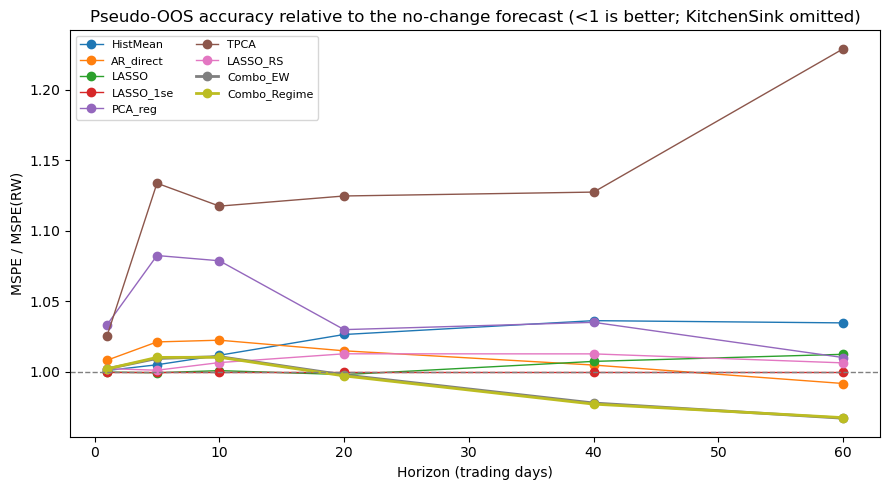

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
for m in [m for m in models if m not in ("RW", "KitchenSink")]:
    g = ev[ev.model == m]
    ax.plot(g["h"], g["MSPE_ratio_vs_RW"], marker="o", lw=2 if m.startswith("Combo") else 1, label=m)
ax.axhline(1, color="grey", lw=1, ls="--")
ax.set_xlabel("Horizon (trading days)"); ax.set_ylabel("MSPE / MSPE(RW)")
ax.set_title("Pseudo-OOS accuracy relative to the no-change forecast (<1 is better; KitchenSink omitted)")
ax.legend(fontsize=8, ncol=2); fig.tight_layout()
fig.savefig(OUT / "mspe_ratio_by_horizon.png", dpi=150); plt.show()

## 13. Robustness: regimes and stability over time

Two regime splits at the forecast origin: realized-volatility regime (threshold = expanding median of past vol) and the HMM regime. Then year by year.

In [20]:
vol_regime = realized_vol_regime(logp)
reg1 = by_group(val, models, vol_regime, "vol_regime")
reg2 = by_group(val, models, regime_label, "hmm_regime")
reg1.to_csv(OUT / "metrics_by_vol_regime.csv", index=False)
reg2.to_csv(OUT / "metrics_by_hmm_regime.csv", index=False)
display(reg1.pivot_table(index=["h", "model"], columns="vol_regime", values="MSPE_ratio_vs_RW").round(3))
reg2.pivot_table(index=["h", "model"], columns="hmm_regime", values="MSPE_ratio_vs_RW").round(3)

vol_regime        high    low
h  model                     
1  AR_direct     1.009  1.005
   Combo_EW      1.003  0.997
   Combo_Regime  1.003  0.997
   HistMean      1.001  1.000
   KitchenSink   1.358  1.374
...                ...    ...
60 LASSO_1se     1.000  1.000
   LASSO_RS      0.996  1.020
   PCA_reg       1.001  1.022
   RW            1.000  1.000
   TPCA          1.175  1.299

[66 rows x 2 columns]

hmm_regime        calm  turbulent
h  model                         
1  AR_direct     1.007      1.009
   Combo_EW      0.998      1.005
   Combo_Regime  0.998      1.005
   HistMean      1.000      1.001
   KitchenSink   1.343      1.373
...                ...        ...
60 LASSO_1se     1.000      1.000
   LASSO_RS      1.009      1.002
   PCA_reg       1.090      0.851
   RW            1.000      1.000
   TPCA          1.366      0.956

[66 rows x 2 columns]

In [21]:
year = pd.Series(logp.index.year, index=logp.index)
yr = by_group(val, models, year, "year")
yr.to_csv(OUT / "metrics_by_year.csv", index=False)
SHOW = ["LASSO", "LASSO_1se", "PCA_reg", "LASSO_RS", "Combo_EW", "Combo_Regime"]
yr[yr.model.isin(SHOW)].pivot_table(index=["h", "model"], columns="year", values="MSPE_ratio_vs_RW").round(3)

year              2016   2017   2018   2019   2020   2021   2022   2023   2024   2025   2026
h  model                                                                                    
1  Combo_EW      0.993  0.994  0.975  0.989  1.018  1.015  1.003  0.996  0.999  0.982  0.998
   Combo_Regime  0.993  0.994  0.975  0.989  1.018  1.015  1.003  0.996  0.999  0.982  0.999
   LASSO         0.998  1.000  0.988  1.001  0.999  1.001  1.005  1.000  1.000  0.994  1.003
   LASSO_1se     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
   LASSO_RS      1.005  0.999  0.993  1.001  1.000  1.006  1.010  1.000  1.000  0.996  1.004
   PCA_reg       0.988  0.998  0.950  0.980  1.118  1.054  1.002  0.994  1.016  0.980  1.017
5  Combo_EW      1.015  0.980  1.004  1.002  1.013  1.036  1.003  0.995  0.995  0.964  1.028
   Combo_Regime  1.014  0.981  1.004  1.002  1.016  1.035  1.002  0.995  0.995  0.964  1.028
   LASSO         1.000  0.998  1.000  1.000  1.000  0.982  1.000  1.000  1.000  0.993  1.004
   LASSO_1se     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
   LASSO_RS      1.000  1.000  1.000  1.000  1.000  1.006  1.000  1.000  1.000  0.996  1.007
   PCA_reg       1.047  0.993  1.010  1.009  1.116  1.186  1.046  1.070  1.035  0.925  1.151
10 Combo_EW      1.028  1.004  1.013  1.001  1.010  1.037  1.016  1.020  0.999  0.949  1.009
   Combo_Regime  1.028  1.004  1.012  1.001  1.010  1.036  1.015  1.018  0.998  0.951  1.009
   LASSO         1.010  0.998  1.000  1.000  1.000  1.004  0.999  1.000  1.000  0.995  1.001
   LASSO_1se     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
   LASSO_RS      1.074  0.999  1.000  1.000  1.000  1.007  0.999  1.000  1.000  0.994  1.001
   PCA_reg       1.085  1.022  0.977  1.043  1.071  1.235  1.151  1.122  1.102  0.950  1.084
20 Combo_EW      1.045  0.972  1.070  1.015  0.967  1.043  0.986  1.025  0.977  0.964  1.019
   Combo_Regime  1.045  0.971  1.065  1.011  0.967  1.042  0.986  1.022  0.978  0.964  1.018
   LASSO         1.001  0.950  1.062  0.962  1.000  1.007  0.960  0.995  1.000  1.000  1.000
   LASSO_1se     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
   LASSO_RS      1.129  0.989  1.056  0.964  1.000  1.020  1.000  0.995  1.000  1.000  1.000
   PCA_reg       1.087  0.976  1.006  1.101  0.944  1.293  1.106  1.084  1.255  0.862  1.077
40 Combo_EW      1.009  0.935  1.043  1.095  0.914  1.116  0.994  1.117  0.965  0.971  1.035
   Combo_Regime  1.009  0.934  1.041  1.087  0.916  1.114  0.997  1.097  0.961  0.968  1.029
   LASSO         1.015  0.933  1.044  1.108  1.000  0.966  1.070  1.009  1.000  0.962  1.000
   LASSO_1se     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
   LASSO_RS      1.046  0.993  1.054  1.131  1.000  0.955  1.069  1.009  1.000  1.000  1.000
   PCA_reg       0.969  0.754  1.004  1.326  0.880  1.506  1.170  1.849  1.401  0.899  1.142
60 Combo_EW      1.024  0.956  1.000  1.061  0.892  1.020  0.928  1.269  0.825  0.974  0.994
   Combo_Regime  1.026  0.937  0.992  1.057  0.898  1.022  0.928  1.248  0.842  0.975  0.992
   LASSO         1.065  0.922  0.972  1.136  1.000  0.957  0.943  0.994  1.000  1.009  1.006
   LASSO_1se     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
   LASSO_RS      1.113  0.945  0.973  1.065  1.000  0.926  0.943  0.994  1.000  1.011  1.006
   PCA_reg       0.916  0.701  0.976  1.120  0.846  1.318  1.305  2.602  1.327  0.920  0.950

## 14. Economic value

Sign rule on h=1 forecasts with `cost_bps` per unit of turnover; buy-and-hold for reference. Returns in log terms.

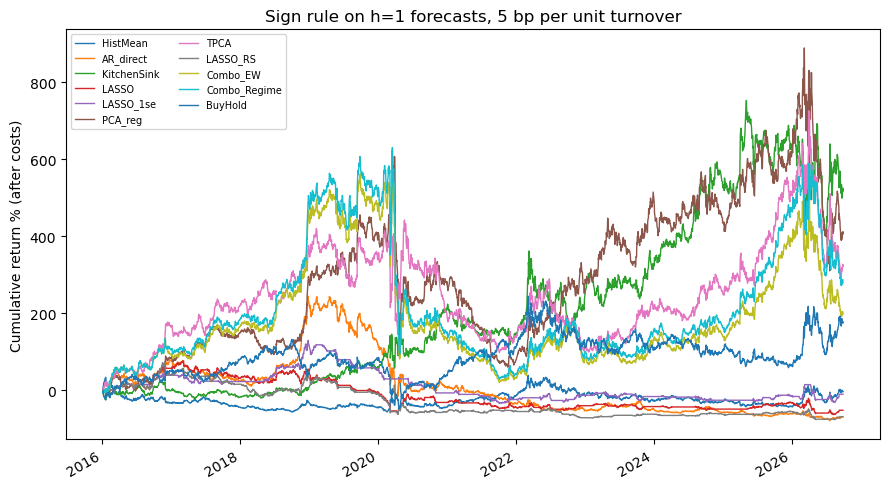

,strategy,ann_log_return_%,ann_vol_%,sharpe,max_drawdown_%,hit_rate,n_position_changes,total_cost_%
0,HistMean,-0.374,41.168,-0.009,-67.690,0.502,6,0.55
1,AR_direct,-10.956,41.154,-0.266,-94.082,0.471,1109,110.85
2,KitchenSink,16.979,41.157,0.413,-44.121,0.520,595,59.45
3,LASSO,-6.903,32.922,-0.210,-79.261,0.498,700,67.70
4,LASSO_1se,-1.045,24.348,-0.043,-71.584,0.493,508,47.40
5,PCA_reg,15.221,41.142,0.370,-77.971,0.497,917,91.65
6,TPCA,13.428,41.146,0.326,-63.554,0.507,857,85.65
7,LASSO_RS,-11.022,32.914,-0.335,-86.369,0.494,666,64.10
8,Combo_EW,10.168,41.159,0.247,-82.479,0.502,889,88.85
9,Combo_Regime,12.429,41.153,0.302,-82.479,0.503,887,88.65


In [22]:
tr, curves = trading(val, models, cfg.trade_horizon, cfg.cost_bps)
tr.to_csv(OUT / "trading_validation.csv", index=False)
if test["y"].notna().any():
    trading(test, models, cfg.trade_horizon, cfg.cost_bps)[0].to_csv(OUT / "trading_test.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 5))
(np.exp(curves) - 1).mul(100).plot(ax=ax, lw=1)
ax.set_ylabel("Cumulative return % (after costs)")
ax.set_title(f"Sign rule on h={cfg.trade_horizon} forecasts, {cfg.cost_bps:.0f} bp per unit turnover")
ax.legend(fontsize=7, ncol=2); fig.tight_layout()
fig.savefig(OUT / "trading_equity_curves.png", dpi=150); plt.show()
tr.round(3)

## 15. What the models use

LASSO selection frequency by variable and by group over time; number of PCA factors and targeted predictors chosen in each window.

,h,variable,selection_freq,group
0,1,own_ret1,0.231,own price
4,1,xle__ret1,0.192,refining / energy
19,1,t10y3m__lvl,0.138,business cycle
8,1,usdcad__ret1,0.123,USD / FX
11,1,breakeven10y__d20,0.123,business cycle
16,1,wei__d4,0.115,business cycle
102,5,own_ret5,0.069,own price
89,5,brent_wti__d5,0.062,refining / energy
107,5,xle__ret5,0.062,refining / energy
77,5,usdnok__ret20,0.038,USD / FX


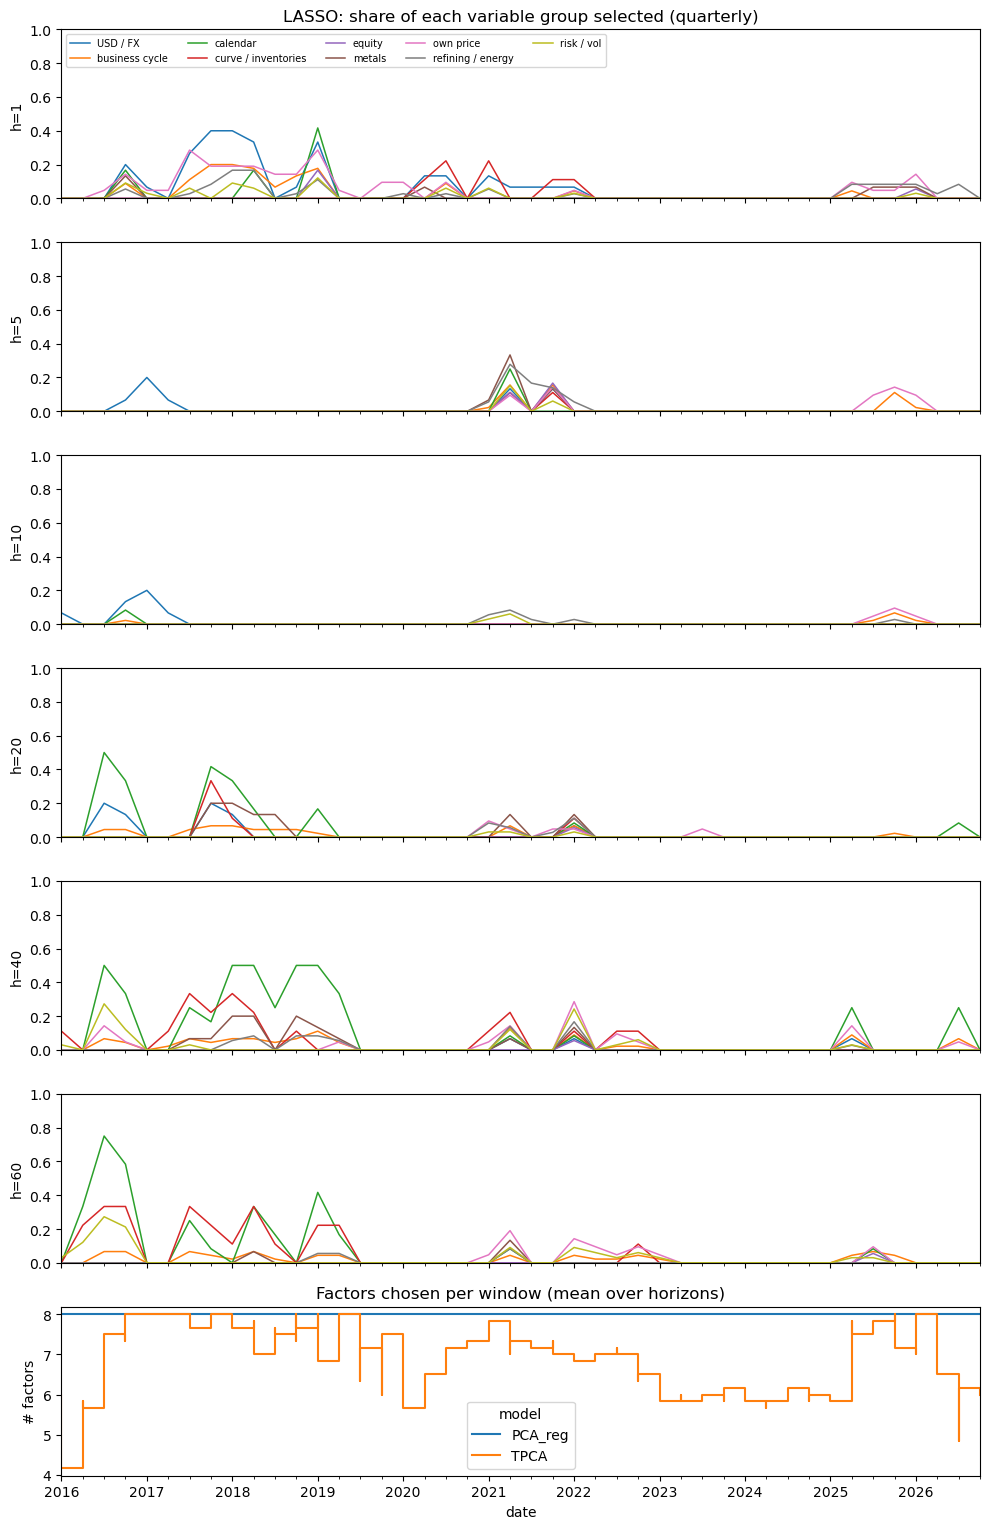

In [23]:
GROUP_PREFIX = [
    ("own price", ("own_",)),
    ("curve / inventories", ("wti_slope", "inv__")),
    ("business cycle", ("wei__", "t10y3m", "curve_10y2y", "ust10y", "breakeven10y")),
    ("refining / energy", ("crack321", "gasoline", "heating_oil", "natgas", "wti_fut", "xle", "brent_wti")),
    ("risk / vol", ("vix", "ovx", "epu")),
    ("USD / FX", ("dxy", "usdcad", "usdnok")),
    ("equity", ("sp500", "eem")),
    ("metals", ("gold", "copper")),
    ("calendar", ("season_",)),
]
def group_of(var):
    for g, prefixes in GROUP_PREFIX:
        if var.startswith(prefixes):
            return g
    return "other"

meta = {"h", "date"}
vcols = [c for c in sel.columns if c not in meta]
freq = (sel.groupby("h")[vcols].apply(lambda g: g.notna().mean()).stack().rename("selection_freq")
        .reset_index().rename(columns={"level_1": "variable"}))
freq = freq[freq.selection_freq > 0].sort_values(["h", "selection_freq"], ascending=[True, False])
freq["group"] = freq["variable"].map(group_of)
freq.to_csv(OUT / "lasso_selection_freq.csv", index=False)
display(freq.groupby("h").head(6).round(3))

hs = sorted(sel["h"].unique())
fig, axes = plt.subplots(len(hs) + 1, 1, figsize=(10, 2.2 * (len(hs) + 1)), sharex=True)
for ax, h in zip(axes, hs):
    g = sel[sel.h == h].set_index("date")[vcols].notna()
    g.T.groupby(group_of).mean().T.resample("QE").mean().plot(ax=ax, lw=1.1, legend=(h == hs[0]))
    ax.set_ylabel(f"h={h}"); ax.set_ylim(0, 1)
axes[0].legend(fontsize=7, ncol=5, loc="upper left")
axes[0].set_title("LASSO: share of each variable group selected (quarterly)")
pk = fit_info[fit_info.model.isin(["PCA_reg", "TPCA"])].pivot_table(index="date", columns="model", values="k", aggfunc="mean")
pk.plot(ax=axes[-1], drawstyle="steps-post"); axes[-1].set_ylabel("# factors")
axes[-1].set_title("Factors chosen per window (mean over horizons)")
fig.tight_layout(); fig.savefig(OUT / "model_selection.png", dpi=150); plt.show()

## 16. Price backtest: forecast vs realized price

Forecasts plotted at their realization date (origin + h trading days). On short horizons every model tracks the price closely, including RW; `RMSE_vs_RW` and the longer horizons are the informative parts.

,sample,h,model,n,MAE,RMSE,MAPE_%,bias(actual-pred),RMSE_vs_RW
0,validation,1,RW,2702,1.192,1.818,1.743,0.024,1.000
1,validation,1,HistMean,2702,1.192,1.819,1.743,0.022,1.000
2,validation,1,AR_direct,2702,1.198,1.827,1.750,0.025,1.005
3,validation,1,KitchenSink,2702,1.412,2.119,2.064,-0.129,1.165
4,validation,1,LASSO,2702,1.191,1.819,1.741,0.020,1.001
...,...,...,...,...,...,...,...,...,...
17,test,5,PCA_reg,1,0.037,0.037,0.035,-0.037,0.037
18,test,5,TPCA,1,1.506,1.506,1.458,-1.506,1.506
19,test,5,LASSO_RS,1,1.000,1.000,0.968,1.000,1.000
20,test,5,Combo_EW,1,0.414,0.414,0.401,0.414,0.414


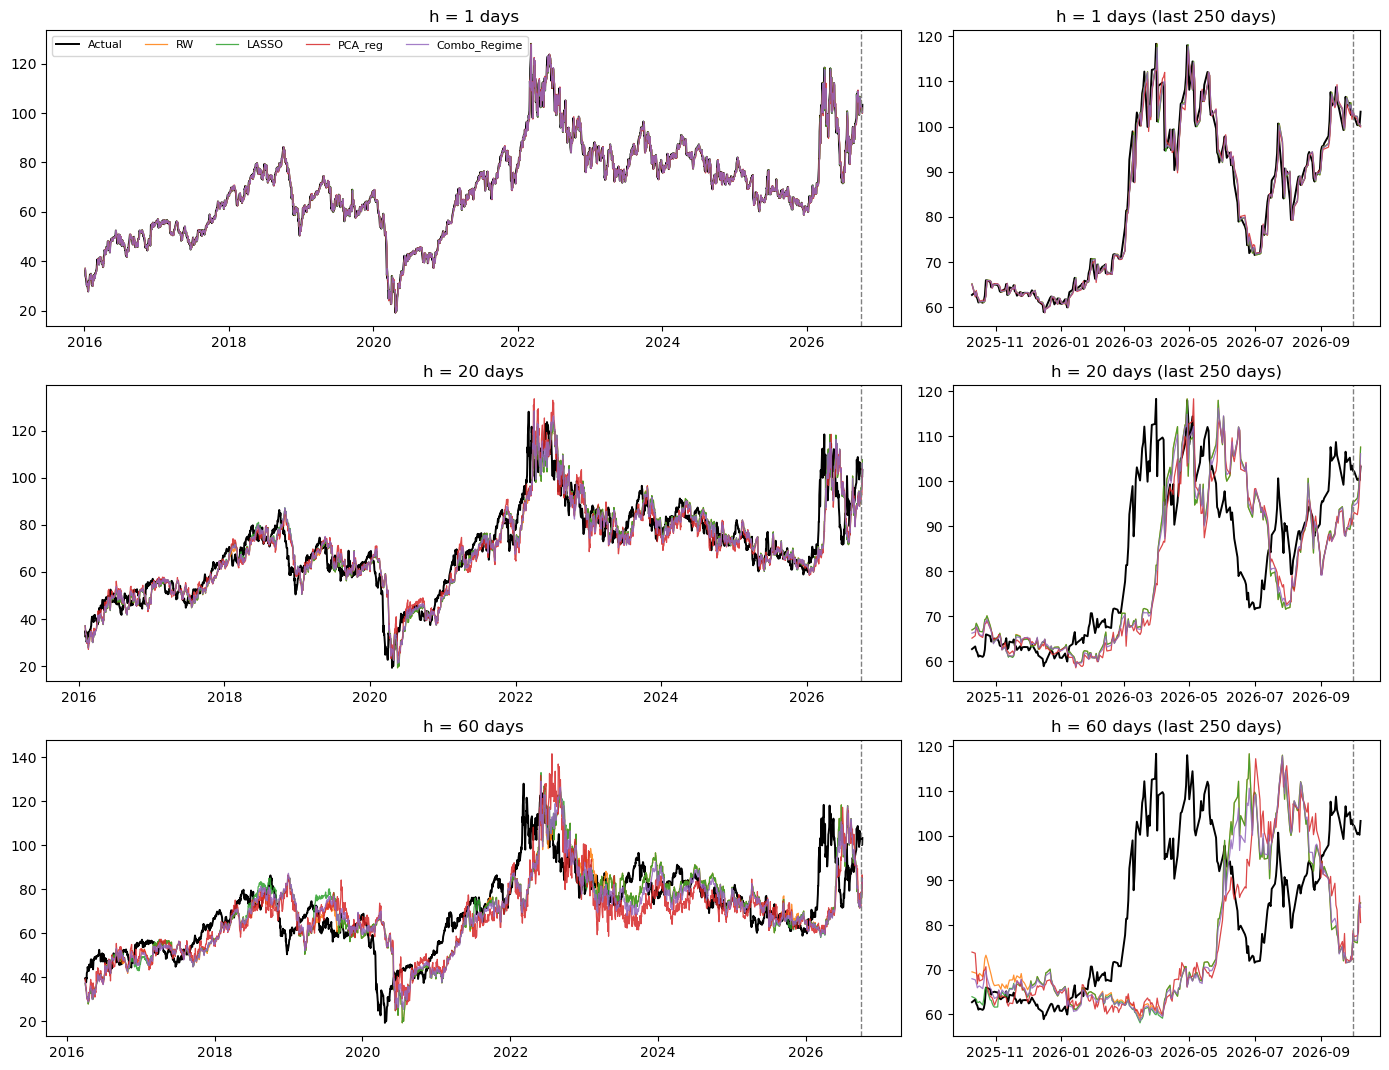

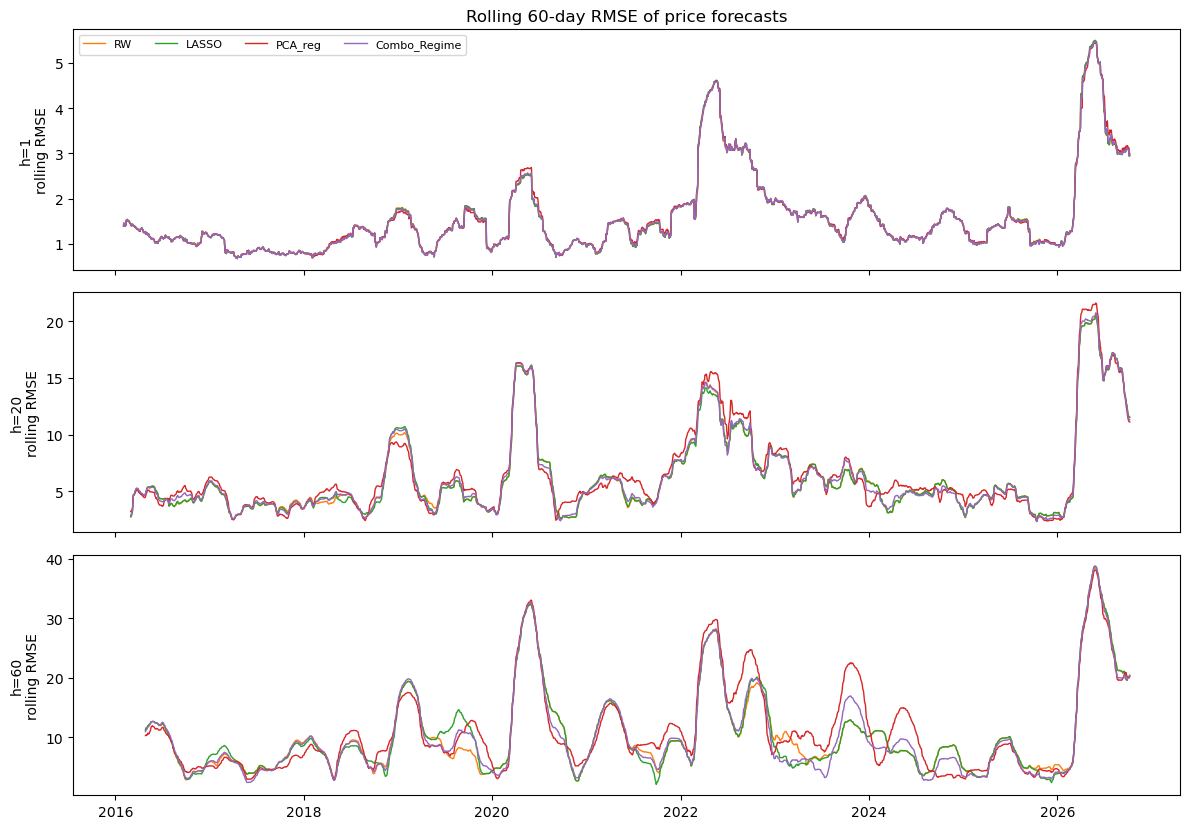

In [24]:
PLOT_MODELS = ["RW", "LASSO", "PCA_reg", "Combo_Regime"]
PLOT_HORIZONS = [h for h in [1, 20, 60] if h in cfg.horizons]
ZOOM_DAYS = 250

def price_backtest(fc, models):
    pb = fc.copy()
    for m in models:
        pb[f"{m}_price"] = pb["P_t"] * np.exp(pb[m])
    pb = pb.rename(columns={"P_true": "actual_price"})
    return pb[["date", "target_date", "h", "P_t", "actual_price"] + [f"{m}_price" for m in models]]

def price_errors(pb, models, label):
    rows = []
    for h, g in pb.dropna(subset=["actual_price"]).groupby("h"):
        a = g["actual_price"].to_numpy()
        rw_rmse = np.sqrt(np.mean((a - g["RW_price"]) ** 2))
        for m in models:
            e = a - g[f"{m}_price"].to_numpy()
            rmse = np.sqrt(np.mean(e ** 2))
            rows.append({"sample": label, "h": h, "model": m, "n": len(a), "MAE": np.mean(np.abs(e)),
                         "RMSE": rmse, "MAPE_%": 100 * np.mean(np.abs(e / a)),
                         "bias(actual-pred)": np.mean(e), "RMSE_vs_RW": rmse / rw_rmse})
    return pd.DataFrame(rows)

pb = price_backtest(fc, models)
pb.to_csv(OUT / "price_backtest.csv", index=False)
perr = pd.concat([price_errors(pb[pb["date"] < TS], models, "validation"),
                  price_errors(pb[pb["date"] >= TS], models, "test")])
perr.to_csv(OUT / "price_errors.csv", index=False)
display(perr.round(3))

colors = dict(zip(PLOT_MODELS, plt.rcParams["axes.prop_cycle"].by_key()["color"][1:]))
fig, axes = plt.subplots(len(PLOT_HORIZONS), 2, figsize=(14, 3.6 * len(PLOT_HORIZONS)),
                         gridspec_kw={"width_ratios": [2, 1]}, squeeze=False)
for r_, h in enumerate(PLOT_HORIZONS):
    g = pb[pb["h"] == h].dropna(subset=["actual_price"]).set_index("target_date")
    for c_, sub in enumerate([g, g.iloc[-ZOOM_DAYS:]]):
        ax = axes[r_, c_]
        ax.plot(sub.index, sub["actual_price"], color="black", lw=1.4, label="Actual")
        for m in PLOT_MODELS:
            ax.plot(sub.index, sub[f"{m}_price"], lw=0.9, alpha=0.85, color=colors[m], label=m)
        if sub.index.max() >= TS:
            ax.axvline(TS, color="grey", ls="--", lw=1)
        ax.set_title(f"h = {h} days" + ("" if c_ == 0 else f" (last {ZOOM_DAYS} days)"))
axes[0, 0].legend(fontsize=8, ncol=len(PLOT_MODELS) + 1, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "price_forecast_vs_actual.png", dpi=150); plt.show()

fig, axes = plt.subplots(len(PLOT_HORIZONS), 1, figsize=(12, 2.8 * len(PLOT_HORIZONS)), sharex=True, squeeze=False)
for ax, h in zip(axes[:, 0], PLOT_HORIZONS):
    g = pb[pb["h"] == h].dropna(subset=["actual_price"]).set_index("target_date")
    for m in PLOT_MODELS:
        err = g["actual_price"] - g[f"{m}_price"]
        ax.plot(err.index, err.pow(2).rolling(60, min_periods=20).mean().pow(0.5), lw=1, color=colors[m], label=m)
    ax.set_ylabel(f"h={h}\nrolling RMSE")
axes[0, 0].legend(fontsize=8, ncol=len(PLOT_MODELS))
axes[0, 0].set_title("Rolling 60-day RMSE of price forecasts")
fig.tight_layout(); fig.savefig(OUT / "price_error_rolling.png", dpi=150); plt.show()

## 17. Daily updating: how forecasts change as new data arrive

A: forecast paths from successive origins. B: forecasts of the same target date made 60, 40, ..., 1 days ahead, and their error by lead time on a common set of target dates.

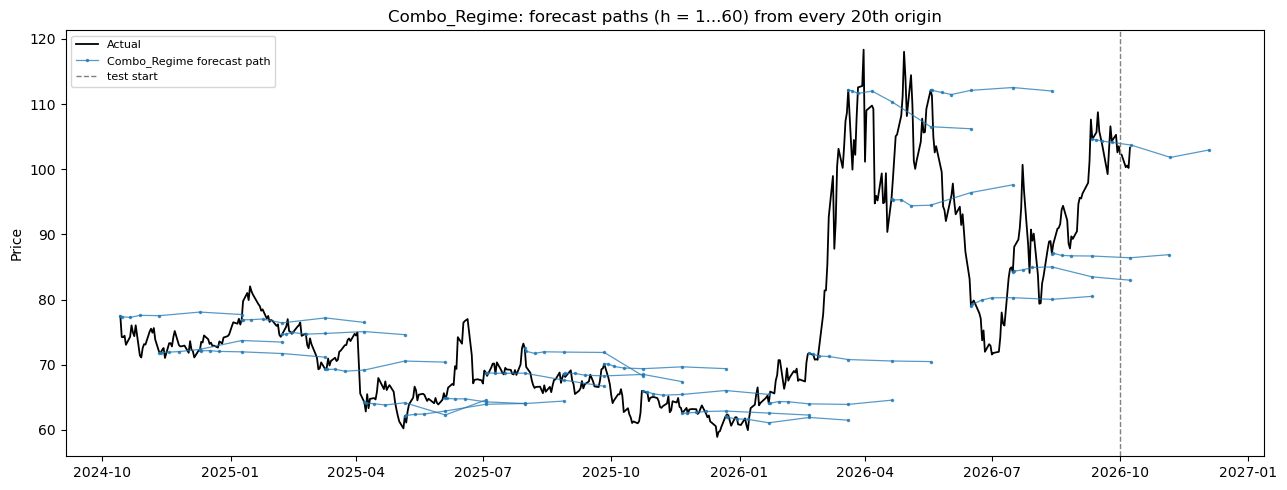

,lead_h,Combo_Regime_RMSE,RW_RMSE,RMSE_ratio_vs_RW
0,1,1.826,1.827,0.999
1,5,3.943,3.926,1.004
2,10,5.381,5.351,1.006
3,20,7.434,7.394,1.005
4,40,10.555,10.467,1.008
5,60,12.716,12.736,0.998


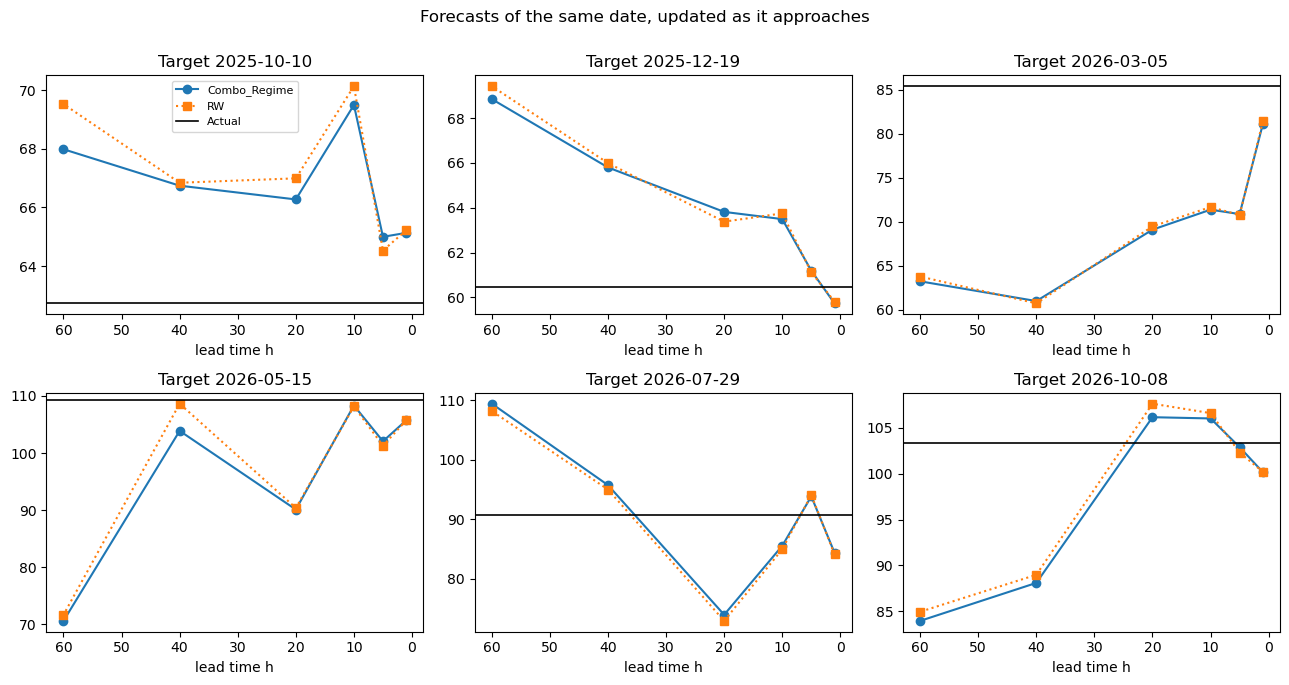

In [25]:
UPD_MODEL = "Combo_Regime"
PATH_EVERY, PATH_LOOKBACK, N_TARGETS = 20, 500, 6
hs_all = sorted(fc["h"].unique())

def _fc_price(df, m):
    return df["P_t"] * np.exp(df[m])

origins = sorted(fc["date"].unique())[-PATH_LOOKBACK:][::PATH_EVERY]
actual = np.exp(logp).loc[origins[0]:]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(actual.index, actual, color="black", lw=1.3, label="Actual")
for j, o in enumerate(origins):
    g = fc[fc["date"] == o].sort_values("h")
    xs = [o] + [d if pd.notna(d) else o + pd.offsets.BDay(int(h)) for d, h in zip(g["target_date"], g["h"])]
    ys = [g["P_t"].iloc[0]] + list(_fc_price(g, UPD_MODEL))
    ax.plot(xs, ys, color="tab:blue", lw=0.9, alpha=0.75, marker=".", ms=3,
            label=f"{UPD_MODEL} forecast path" if j == 0 else None)
if actual.index.max() >= TS:
    ax.axvline(TS, color="grey", ls="--", lw=1, label="test start")
ax.set_ylabel("Price"); ax.legend(fontsize=8)
ax.set_title(f"{UPD_MODEL}: forecast paths (h = {hs_all[0]}...{hs_all[-1]}) from every {PATH_EVERY}th origin")
fig.tight_layout(); fig.savefig(OUT / "update_forecast_paths.png", dpi=150); plt.show()

tgt = fc.dropna(subset=["y"]).copy()
tgt["fc_price"] = _fc_price(tgt, UPD_MODEL)
piv = tgt.pivot_table(index="target_date", columns="h", values="fc_price")
piv_rw = tgt.pivot_table(index="target_date", columns="h", values="P_t")
act_T = tgt.groupby("target_date")["P_true"].first()
common = piv.dropna().index
lead = []
for h in hs_all:
    e_m, e_r = act_T.loc[common] - piv.loc[common, h], act_T.loc[common] - piv_rw.loc[common, h]
    lead.append({"lead_h": h, f"{UPD_MODEL}_RMSE": np.sqrt(np.mean(e_m ** 2)),
                 "RW_RMSE": np.sqrt(np.mean(e_r ** 2))})
lead = pd.DataFrame(lead)
lead["RMSE_ratio_vs_RW"] = lead[f"{UPD_MODEL}_RMSE"] / lead["RW_RMSE"]
lead.to_csv(OUT / "update_error_by_lead.csv", index=False)
display(lead.round(3))

ex = common[-250:][np.linspace(0, min(249, len(common) - 1), N_TARGETS).astype(int)]
fig, axes = plt.subplots(int(np.ceil(N_TARGETS / 3)), 3, figsize=(13, 3.4 * np.ceil(N_TARGETS / 3)))
for ax, T in zip(np.ravel(axes), ex):
    ax.plot(hs_all, piv.loc[T, hs_all], marker="o", label=UPD_MODEL)
    ax.plot(hs_all, piv_rw.loc[T, hs_all], marker="s", ls=":", label="RW")
    ax.axhline(act_T.loc[T], color="black", lw=1.2, label="Actual")
    ax.invert_xaxis(); ax.set_title(f"Target {pd.Timestamp(T).date()}"); ax.set_xlabel("lead time h")
np.ravel(axes)[0].legend(fontsize=8)
fig.suptitle("Forecasts of the same date, updated as it approaches", y=1.0)
fig.tight_layout(); fig.savefig(OUT / "update_same_target.png", dpi=150); plt.show()

## 18. Latest forecast and running log

Each run appends today's forecasts to `forecast_log.csv`, which becomes the test-period record. The latest regime forecast is shown too. `target_date_approx` uses business days and ignores exchange holidays.

In [26]:
def live_table(fc, models):
    last = fc["date"].max()
    rows = []
    for _, r in fc[fc["date"] == last].iterrows():
        tgt = r["target_date"] if pd.notna(r["target_date"]) else last + pd.offsets.BDay(int(r["h"]))
        row = {"origin_date": last.date(), "h": int(r["h"]),
               "target_date_approx": pd.Timestamp(tgt).date(), "P_t": r["P_t"],
               "P_turbulent_now": r["regime_p"], "P_turbulent_at_target": r["p_logit"]}
        for m in models:
            row[f"{m}_price"] = r["P_t"] * np.exp(r[m])
        rows.append(row)
    return pd.DataFrame(rows)

def append_log(path, live):
    if path.exists():
        old = pd.read_csv(path, parse_dates=["origin_date"])
        old["origin_date"] = old["origin_date"].dt.date
        live = pd.concat([old, live]).drop_duplicates(["origin_date", "h"], keep="last")
    live.sort_values(["origin_date", "h"]).to_csv(path, index=False)

live = live_table(fc, models)
live.to_csv(OUT / "live_forecast.csv", index=False)
append_log(OUT / "forecast_log.csv", live)
live[["origin_date", "h", "target_date_approx", "P_t", "P_turbulent_now", "P_turbulent_at_target",
      "RW_price", "LASSO_price", "LASSO_1se_price", "PCA_reg_price", "Combo_Regime_price"]].round(3)

,origin_date,h,target_date_approx,P_t,P_turbulent_now,P_turbulent_at_target,RW_price,LASSO_price,LASSO_1se_price,PCA_reg_price,Combo_Regime_price
0,2026-10-08,1,2026-10-09,103.31,0.061,0.033,103.31,103.31,103.31,103.049,103.384
1,2026-10-08,5,2026-10-15,103.31,0.061,0.149,103.31,103.31,103.31,104.269,103.709
2,2026-10-08,10,2026-10-22,103.31,0.061,0.264,103.31,103.31,103.31,104.198,103.706
3,2026-10-08,20,2026-11-05,103.31,0.061,0.273,103.31,103.31,103.31,103.420,103.757
4,2026-10-08,40,2026-12-03,103.31,0.061,0.340,103.31,103.31,103.31,101.300,102.954
5,2026-10-08,60,2026-12-31,103.31,0.061,0.590,103.31,103.31,103.31,96.685,102.544


## 19. Optional: robustness to the window length, and a look-ahead check

`pipeline()` reruns everything from features to combinations. The look-ahead check scrambles all data after a cut-off date (daily, weekly and EIA) and confirms that every forecast and regime probability on or before the cut-off is unchanged. Worth running once on the real data and citing in the report.

In [27]:
def pipeline(prices, eia, weekly, cfg, verbose=False):
    X0, Y0, lp = build_features(prices, eia, weekly, cfg.target, cfg)
    P0, log0 = run_regime_id(lp, cfg, verbose=verbose)
    X1 = add_regime_features(X0, P0, cfg)
    rp0 = run_regime_pred(X1, P0, log0, cfg, verbose=verbose)
    fc0, _, _, mods = run_backtest(X1, Y0, lp, cfg, verbose=verbose)
    return add_combinations(fc0, rp0, cfg), rp0, P0, mods + ["Combo_EW", "Combo_Regime"]

RUN_ROBUST = False
if RUN_ROBUST:
    rob = []
    for w in cfg.robustness_windows:
        fc_w, _, _, m_w = pipeline(prices, eia, weekly, replace(cfg, window=w))
        e = evaluate(fc_w[fc_w["date"] < TS], m_w)
        e.insert(0, "window_days", w)
        rob.append(e)
        print(f"window={w} done")
    rob = pd.concat(rob)
    rob.to_csv(OUT / "robustness_windows.csv", index=False)
    display(rob.pivot_table(index=["h", "model"], columns="window_days", values="MSPE_ratio_vs_RW").round(3))

In [28]:
RUN_LEAK_CHECK = False
if RUN_LEAK_CHECK:
    c2 = replace(cfg, oos_start="2018-06-01", horizons=[1, 20], window=756, cv_folds=3, n_alphas=15)
    end, cut = pd.Timestamp("2020-12-31"), pd.Timestamp("2020-03-02")
    rng = np.random.default_rng(1)
    def scramble(df):
        df = df.copy(); m = df.index > cut
        df.loc[m] = df.loc[m] * np.exp(rng.normal(0, 0.2, size=df.loc[m].shape))
        return df
    p_a, e_a = prices.loc[:end], (eia.loc[:end] if len(eia) else eia)
    w_a = {n: (s.loc[:end], l) for n, (s, l) in weekly.items()}
    p_b, e_b = scramble(p_a), (scramble(e_a) if len(e_a) else e_a)
    w_b = {n: (scramble(s.to_frame()).iloc[:, 0], l) for n, (s, l) in w_a.items()}
    fa, ra, Pa, mods = pipeline(p_a, e_a, w_a, c2)
    fb, rb, Pb, _ = pipeline(p_b, e_b, w_b, c2)
    A_ = fa[fa.date <= cut].set_index(["date", "h"])[mods]
    B_ = fb[fb.date <= cut].set_index(["date", "h"])[mods]
    d_fc = (A_ - B_).abs().max().max()
    d_rp = (ra[ra.date <= cut].set_index(["date", "h"])[["p_logit", "p_markov"]]
            - rb[rb.date <= cut].set_index(["date", "h"])[["p_logit", "p_markov"]]).abs().max().max()
    d_P = (Pa.loc[:cut] - Pb.loc[:cut]).abs().max().max()
    later = (fa[fa.date > cut].set_index(["date", "h"])[mods] - fb[fb.date > cut].set_index(["date", "h"])[mods]).abs().max().max()
    print(f"origins checked: {len(A_)}   max change: forecasts {d_fc:.2e}, regime forecasts {d_rp:.2e}, "
          f"regime probs {d_P:.2e}   (after cut-off: {later:.2e})")
    print("PASS: no look-ahead" if max(d_fc, d_rp, d_P) < 1e-9 and later > 1e-6 else "CHECK FAILED")

## Notes and limitations

- **Revisions.** WEI and other macro series are revised; FRED serves the latest vintage. Strictly real-time work would use ALFRED vintages. Market prices are not revised.
- **Release dates** are approximated (period date + 6 days for weekly series). EIA's actual schedule shifts around holidays.
- **Curve slope** uses WTI contracts because EIA publishes them; Brent curve data are not freely available. EIA files are updated weekly, so the last few days can be filled forward (up to `slow_ffill_limit`).
- **Regimes.** Few full turbulent episodes since 2016 (2020, 2022, 2026), so regime-conditional estimates rest on limited data. Regime labels are model-based, not observed.
- **Overlapping targets.** For h > 1, consecutive forecast errors overlap, so DM/CW use HAC variances and the PT test overstates significance.
- **Not included:** MIDAS (in v1), news/sentiment, CFTC positioning, Brent curve.